# Counting vehicles by class for junction signal timing (UVH-26, YOLOv8)

**Yash Renwa · BITS ID 2025AG05357** · AIML ZG525 Computer Vision, EC-1 Assignment 1 · Track B (object detection)

This notebook runs top to bottom on a free Colab T4 (*Runtime → Change runtime type → T4 GPU*). Its sections follow the eight steps of the report.

- **`RUN_TRAINING`** (next cell): `True` trains both models, reusing any run already finished on Drive; `False` skips training and evaluates the saved weights.
- **`EVALUATE_TEST`** (next cell): `True` opens the sealed test set. Everything it uses (checkpoints, thresholds) was fixed on val first.
- The dataset is downloaded from the Hugging Face Hub at a pinned revision; no data files are embedded.
- Every result in the report appears in a cell output below, except the split-audit figures (the 40-frame audit and the 88 labelled pairs), which are in the repository's `results/` folder.
- Optional Colab secrets: `HF_TOKEN` (faster Hub downloads) and `GITHUB_TOKEN` (only needed while the repository is private).

### How to run or check this notebook

**Code and data are public.** Code, frozen split and this notebook: [github.com/YashRenwa/uvh26-pcu-counting](https://github.com/YashRenwa/uvh26-pcu-counting) ([open in Colab](https://colab.research.google.com/github/YashRenwa/uvh26-pcu-counting/blob/main/notebooks/uvh26_signal_counting.ipynb)). Dataset: [UVH-26 on Hugging Face](https://huggingface.co/datasets/iisc-aim/UVH-26) (CC BY 4.0, not gated); the notebook downloads the files it needs. No GitHub token is needed. An `HF_TOKEN` Colab secret is optional and only avoids Hugging Face rate limits during the image download.

**A. Full re-run (about 3 hours on a T4).** Run all with the settings as they are. The notebook downloads the 4,000 pool images (about 13.6 GB), prepares them, trains both models and evaluates them, saving to `MyDrive/uvh26` in your Google Drive (about 2 GB). GPU training is not bit-exact, so the numbers come out close to the outputs below, not identical.

**B. Quick check with my trained models (no training).** My prepared images and both training runs are in a view-only Drive folder: [uvh26 on Google Drive](https://drive.google.com/drive/folders/1waD4GDFYlR4HbmIuBnGYQQRfzcw3B28O?usp=sharing).
1. Open the link and add a shortcut to the folder in your My Drive (folder menu → *Organize* → *Add shortcut* → *My Drive*). Colab only sees My Drive.
2. In the settings cell below, set `RUN_TRAINING = False` and `DRIVE_ROOT = "/content/uvh26"`.
3. Insert the cell below as the first code cell, then *Run all*. It copies the folder to Colab's local disk, because the notebook writes its results next to the data and the shared folder is read-only. Saved evaluations (`runs/eval`, `results`) are not copied, so every number is recomputed from the trained weights. They should match the outputs below, up to small differences from GPU kernels and a newer Colab PyTorch.

```python
from google.colab import drive
drive.mount("/content/drive")
SRC = "/content/drive/MyDrive/uvh26"  # the shortcut to the shared folder
!mkdir -p /content/uvh26/runs /content/uvh26/prepared
!cp -r {SRC}/weights /content/uvh26/
!cp -r {SRC}/runs/mv {SRC}/runs/st {SRC}/runs/pilot_frozen_mv {SRC}/runs/pilot_full_mv /content/uvh26/runs/
!cp {SRC}/prepared/clip_embeddings.npz {SRC}/prepared/thumbnails.npz /content/uvh26/prepared/
!cp -r {SRC}/prepared/images /content/uvh26/prepared/
```


In [1]:
# ---- Run settings: the only cell that needs editing ----
RUN_TRAINING = True   # False: skip training, evaluate the weights saved under DRIVE_ROOT/runs
EVALUATE_TEST = True  # opens the sealed test set; the thresholds were frozen on val (7 Oct 2026) beforehand
REPO_URL = "https://github.com/YashRenwa/uvh26-pcu-counting.git"
COMMIT = "ee0e619e409895c038d2bab17c528c41662e461b"  # code pinned for the submission run ("main" follows the latest)
DRIVE_ROOT = "/content/drive/MyDrive/uvh26"

In [2]:
import os, subprocess, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    repo_dir = Path("/content/uvh26-pcu-counting")
    if not repo_dir.exists():
        try:
            token = userdata.get("GITHUB_TOKEN")  # only needed for a private repo
        except Exception:
            token = None
        url = REPO_URL.replace("https://", f"https://{token}@") if token else REPO_URL
        subprocess.run(f"git clone -q {url} {repo_dir}", shell=True, check=True)
    os.chdir(repo_dir)
    # Always run exactly what is on GitHub: a branch name follows origin, a hash is used as is.
    # -f discards edits made inside this Colab clone (e.g. regenerated results/); Drive is untouched.
    sh("git fetch -q origin")
    is_branch = subprocess.run(f"git rev-parse -q --verify origin/{COMMIT}", shell=True, capture_output=True).returncode == 0
    sh(f"git checkout -q -f --detach {'origin/' + COMMIT if is_branch else COMMIT}")
    # Keep Colab's preinstalled torch/opencv/numpy (CUDA-matched, no restart); pin the rest.
    sh("grep -v colab-skip requirements.txt > /tmp/req-colab.txt && pip install -q -r /tmp/req-colab.txt")
    os.environ.update({
        "UVH_RAW_ROOT": "/content/raw",              # original PNGs on fast local disk
        "UVH_DATA_ROOT": f"{DRIVE_ROOT}/prepared",   # JPEGs + labels survive a disconnect
        "UVH_RUNS_ROOT": f"{DRIVE_ROOT}/runs",
        "UVH_WEIGHTS_DIR": f"{DRIVE_ROOT}/weights",
        "UVH_DATASETS_ROOT": "/content/datasets",   # training reads from local disk, not Drive
        "UVH_RESULTS_DIR": f"{DRIVE_ROOT}/results",  # results/*.json and figures survive the session
    })
else:
    repo_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(repo_dir)

sys.path.insert(0, str(repo_dir))
commit = subprocess.run("git rev-parse --short HEAD", shell=True, capture_output=True, text=True).stdout.strip()
print("repo:", repo_dir, "| commit:", commit or "(no commits yet)")

Mounted at /content/drive
$ git fetch -q origin
$ git checkout -q -f --detach ee0e619e409895c038d2bab17c528c41662e461b
$ grep -v colab-skip requirements.txt > /tmp/req-colab.txt && pip install -q -r /tmp/req-colab.txt
repo: /content/uvh26-pcu-counting | commit: ee0e619


In [3]:
import torch
from src.common import library_versions, load_config, set_seed

SMOKE = os.environ.get("UVH_SMOKE") == "1"  # quick CPU check on a 20-image subset; leave unset on Colab
cfg = load_config(smoke=SMOKE)
set_seed(cfg["seed"])
print("seed:", cfg["seed"])
for name, version in library_versions().items():
    print(f"  {name:16s} {version}")
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
print("paths:", {k: str(v) for k, v in cfg["paths"].items()})

seed: 42
  python           3.13.15
  numpy            2.1.3
  matplotlib       3.10.0
  torch            2.11.0+cu130
  torchvision      0.26.0+cu130
  opencv-python    5.0.0.93
  transformers     5.18.0
  ultralytics      8.4.173
  huggingface-hub  1.33.0
  pandas           2.2.3
  pyyaml           6.0.3
  tqdm             4.67.3
device: Tesla T4
paths: {'raw_root': '/content/raw', 'data_root': '/content/drive/MyDrive/uvh26/prepared', 'labels_root': '/content/uvh26-pcu-counting/data/labels', 'runs_root': '/content/drive/MyDrive/uvh26/runs', 'weights_dir': '/content/drive/MyDrive/uvh26/weights', 'datasets_root': '/content/datasets', 'splits_dir': '/content/uvh26-pcu-counting/splits', 'results_dir': '/content/drive/MyDrive/uvh26/results', 'tags_file': '/content/uvh26-pcu-counting/analysis/phase6_tags.csv'}


## 1. Problem and task type

Green time at a signalised junction is shared according to the demand on each approach, measured in Passenger Car Units (PCU, IRC:106-1990): a bus or truck counts about 3.3 cars, an auto-rickshaw 2 and a two-wheeler 0.75. The system therefore has to produce a **count per vehicle class** for every camera frame, which is then weighted into PCU.

That makes this an object-detection task. Classification gives one label per image and cannot count: one bus and five buses look the same to it. Segmentation would add per-pixel masks that cost more to label and compute without changing the count, and UVH-26 has no masks. Detection is the smallest output that supports counting: one box and one class per vehicle.

## 2. Data and split

**Source.** UVH-26 (IISc AIM with the Bengaluru Traffic Police), **CC BY 4.0**, downloaded from the Hugging Face Hub at the revision pinned in `configs/base.yaml`. The full set is 26,646 PNGs (90 GB), so I fetch only the four annotation JSONs and a seeded pool of 4,000 images (`splits/pool.csv`). That is small enough to train two models on a free T4.

**Pool.** STAPLE labels exist for only 81% of images (MV covers all), so I draw the pool from images that carry both label sets. The MV and STAPLE runs then train on identical images.

**Pseudo-cameras.** UVH-26 has no camera ids, and a fixed CCTV camera produces many near-identical frames, so a random split puts the same camera on both sides. I link two images when the correlation **g** of their 64×36 grayscale *gradient-magnitude* thumbnails is ≥ 0.48, and take connected components as pseudo-cameras. A fixed camera keeps its static edges at the same pixels, so g survives lighting, glare and colour-vs-IR changes. CLIP ViT-B/32 cosine and intensity correlation did not: CLIP chained different cameras into giant groups (35% of the pool at cosine ≥ 0.92), and on 88 visually labelled hard pairs g separated cameras best (AUC 0.97, against 0.80 for CLIP).

**Split.** Whole pseudo-cameras are split 60/20/20, with the seed chosen from 50 for the best class balance on label counts alone, before any training. A **purge** then moves any val/test image that has a train image at g ≥ 0.36 (with its pseudo-camera) into train, repeating until none is left. A random audit of 40 test images still finds a same-camera train image for 7 of them (≈ 17.5%), which I report as residual leakage rather than claim zero.

**Frozen split.** The split was built once and committed (`splits/`, with a checksum in `splits/test.sha256`). CLIP outputs differ slightly between CPU and GPU, so this notebook recomputes the grouping only to show the evidence; it trains and evaluates on the committed split after verifying the test-set checksum.

In [4]:
import pandas as pd
from IPython.display import Image, display
from src import cluster, download, prepare, split

FIGS = cfg["paths"]["results_dir"] / "figures"
pool = download.select_pool(cfg)   # reads splits/pool.csv from the repo
print(f"pool: {len(pool)} images with both MV and STAPLE labels")
print(pool.groupby(["official_split", "subfolder"]).size().rename("images").to_string())
download.download_pool(cfg, pool)  # PNGs to local disk; skips images already prepared on Drive

pool: 4000 images with both MV and STAPLE labels
official_split  subfolder
train           000          785
                001          711
                002          768
                003          732
                004          205
val             000          743
                001           56
pool 4000 images, 4000 already prepared, 0 to download


Resize to 1280 px on the long side (JPEG quality 95) and write YOLO labels twice, once from MV and once from STAPLE, dropping the 429 exact duplicate boxes in the STAPLE file. YOLO box coordinates are normalised, so they need no rescaling.

resize: 100%|██████████| 4000/4000 [00:01<00:00, 2688.00it/s]


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

{'images': 4000, 'official_split': {'train': 3201, 'val': 799}, 'output_size_wh': [1280, 720], 'jpeg_total_mb': 1431.4, 'boxes': {'mv': 48932, 'st': 51780}, 'boxes_per_image': {'mv': 12.23, 'st': 12.95}, 'exact_duplicate_boxes_dropped': {'mv': 0, 'st': 429}}


,MV,ST
Hatchback,4664,4765
Sedan,2443,2894
SUV,1874,2450
MUV,938,1599
Bus,1422,1410
Truck,2140,2836
Three-wheeler,7895,7783
Two-wheeler,23628,23400
LCV,2675,2918
Mini-bus,130,181


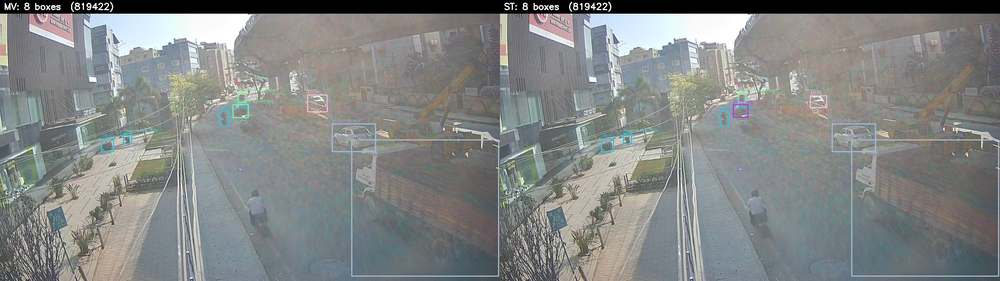

In [5]:
prep = prepare.run(cfg, pool)
print({k: v for k, v in prep.items() if k not in ("class_counts", "subfolders")})
display(pd.DataFrame(prep["class_counts"]).rename(columns=str.upper))
display(Image(filename=str(prepare.draw_labels(cfg, pool["stem"].iloc[0], FIGS / "labels_mv_vs_st.jpg")), width=900))

### Pseudo-cameras and the official split's leakage

In [6]:
clu = cluster.run(cfg)
pc, lk, cal = clu["pseudo_cameras"], clu["leakage"], clu["calibration"]
print(f"linking rule: {clu['rule']} | {pc['groups']} pseudo-cameras | {pc['singletons']} singletons | largest {pc['largest_group']} images")
print(f"calibration (equal cameras): {cal['groups']} groups, {cal['singletons_pct_of_pool']}% singletons")
print(f"LEAKAGE: {lk['val_images_sharing_camera_with_train']} of {lk['val_images']} official-val images "
      f"({lk['leakage_val_share']:.1%}) share a pseudo-camera with an official-train image")
if clu["frozen_groups_used"]:
    print("frozen groups used; recomputed grouping identical:", clu["recomputed_groups_identical"])
display(pd.DataFrame(clu["rule_sweep"]).set_index("setting"))

Using frozen /content/uvh26-pcu-counting/splits/groups.csv; recomputed grouping identical: True
linking rule: g >= 0.48 | 3083 pseudo-cameras | 2703 singletons | largest 65 images
calibration (equal cameras): 2129 groups, 24.0% singletons
LEAKAGE: 247 of 799 official-val images (30.9%) share a pseudo-camera with an official-train image
frozen groups used; recomputed grouping identical: True


,rule,groups,singletons_pct_of_pool,leakage_pct,edges,largest_group,largest_group_pct_of_pool,d_groups,d_singletons_pp,calib_distance
setting,,,,,,,,,,
calibration,"Poisson, 2,800 equal cameras",2129,24.0,68.1,NaN,NaN,NaN,NaN,NaN,NaN
A_tau0.90,CLIP >= 0.90,856,19.9,79.2,33438.0,3010.0,75.2,-1273.0,-4.1,0.622
A_tau0.92,CLIP >= 0.92,2245,51.1,47.3,3968.0,1415.0,35.4,116.0,27.1,1.130
A_tau0.94,CLIP >= 0.94,3595,84.4,14.5,545.0,33.0,0.8,1466.0,60.4,2.609
A_tau0.96,CLIP >= 0.96,3901,95.7,4.0,111.0,8.0,0.2,1772.0,71.7,3.101
B_tau0.88_r0.6,CLIP >= 0.88 AND r >= 0.60,3016,66.0,33.0,2127.0,170.0,4.2,887.0,42.0,1.799
B_tau0.88_r0.7,CLIP >= 0.88 AND r >= 0.70,3385,77.0,22.1,1088.0,39.0,1.0,1256.0,53.0,2.286
B_tau0.88_r0.8,CLIP >= 0.88 AND r >= 0.80,3689,87.5,11.6,421.0,21.0,0.5,1560.0,63.5,2.745
B_tau0.90_r0.6,CLIP >= 0.90 AND r >= 0.60,3198,71.2,27.4,1571.0,58.0,1.5,1069.0,47.2,2.030


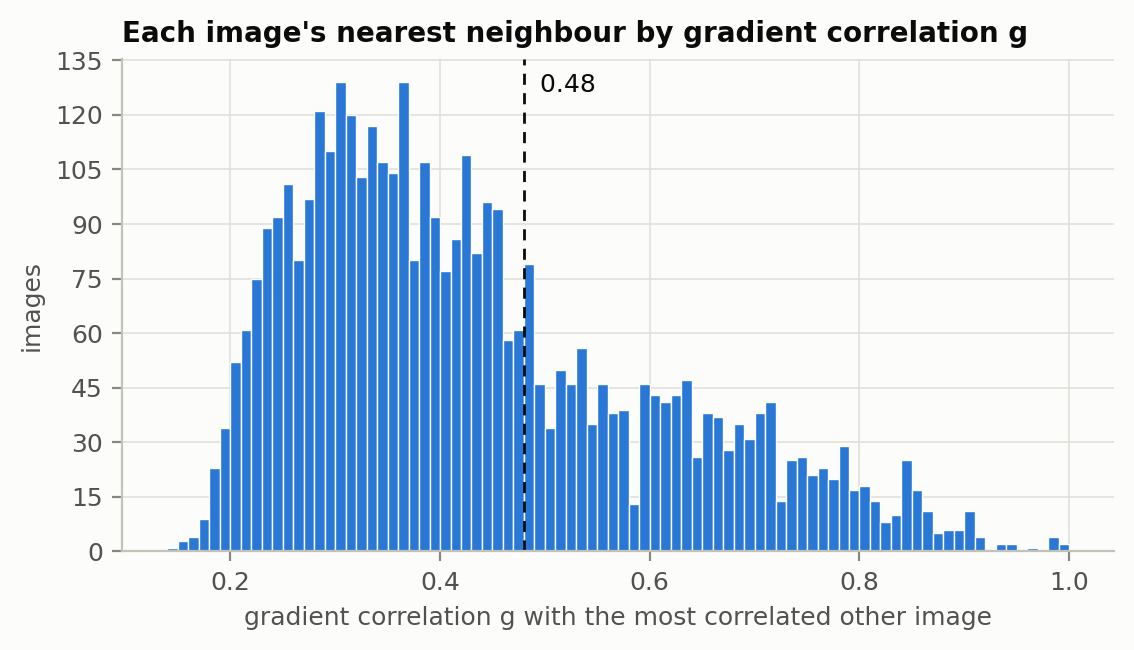

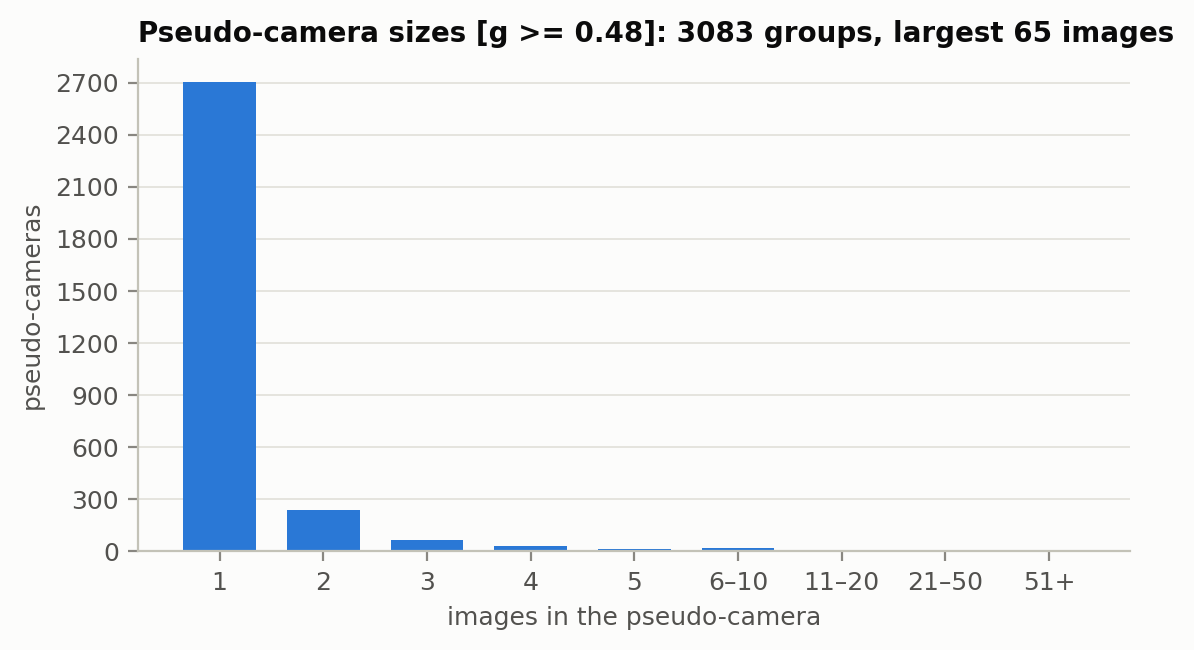

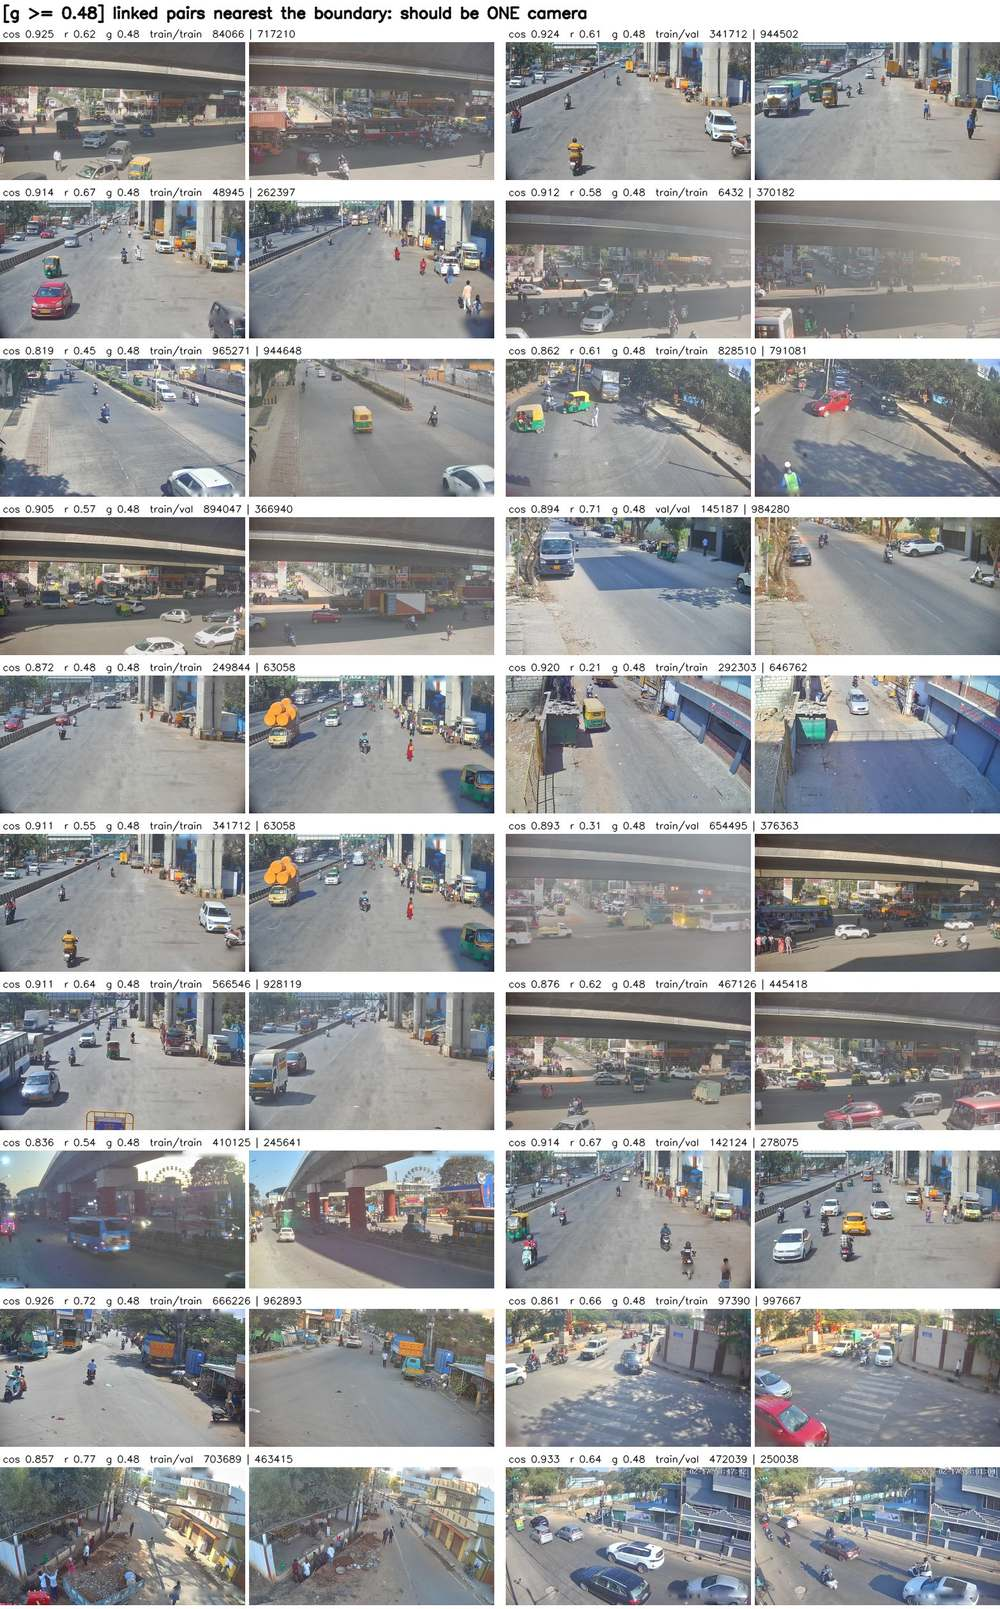

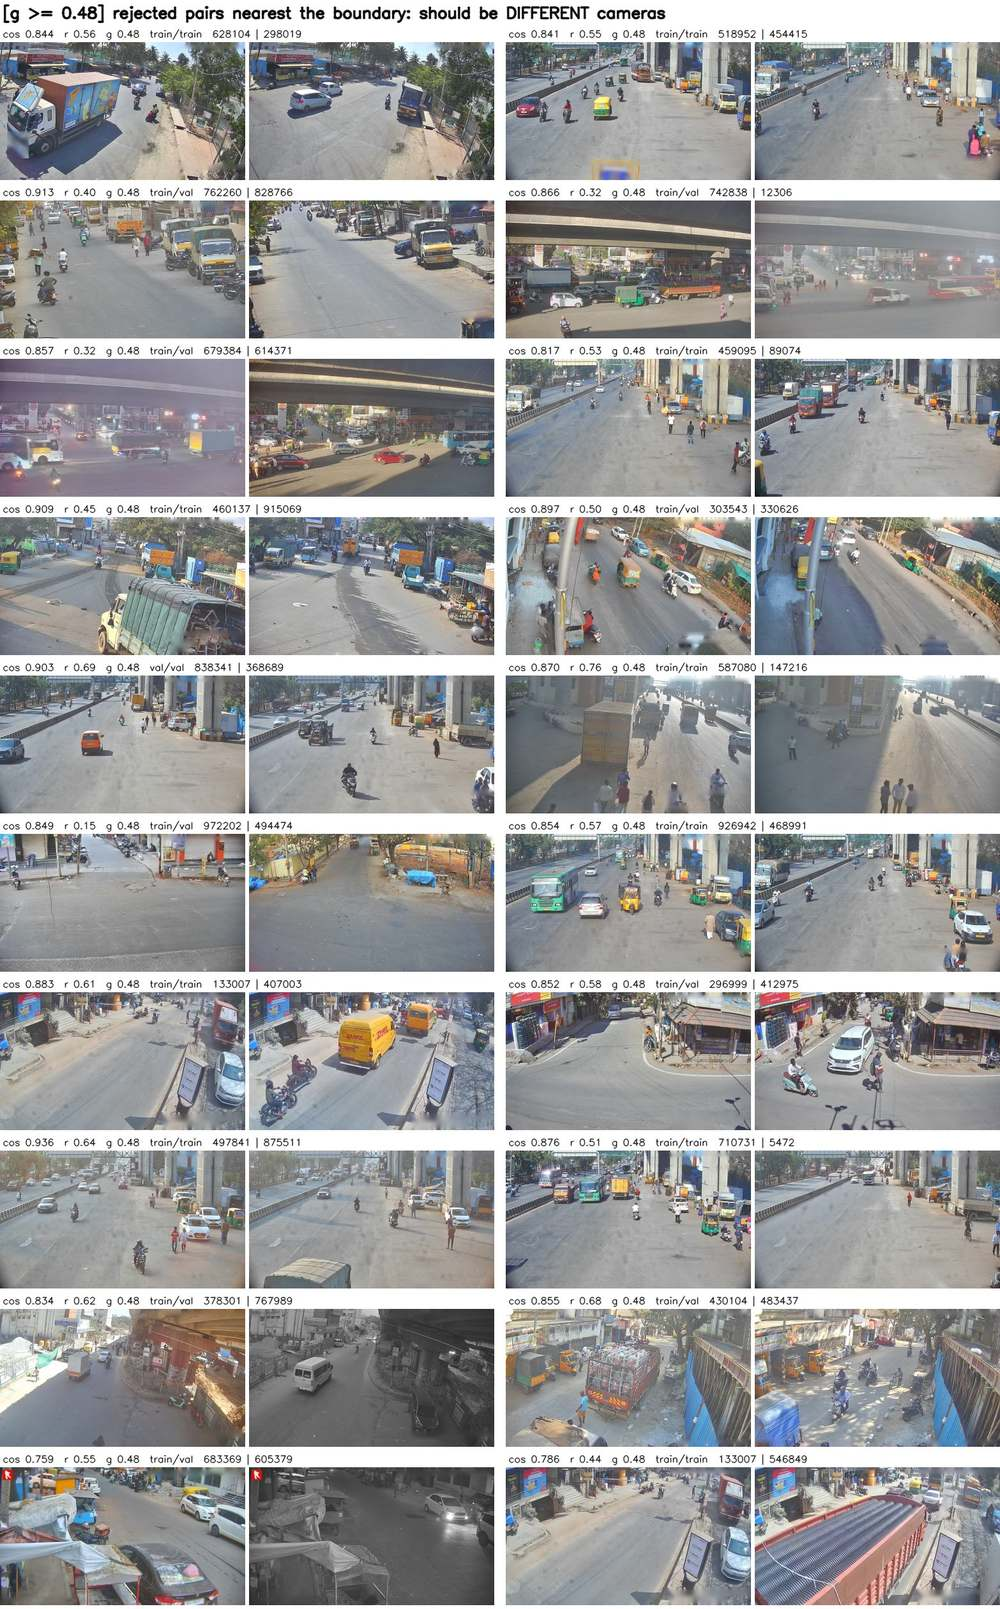

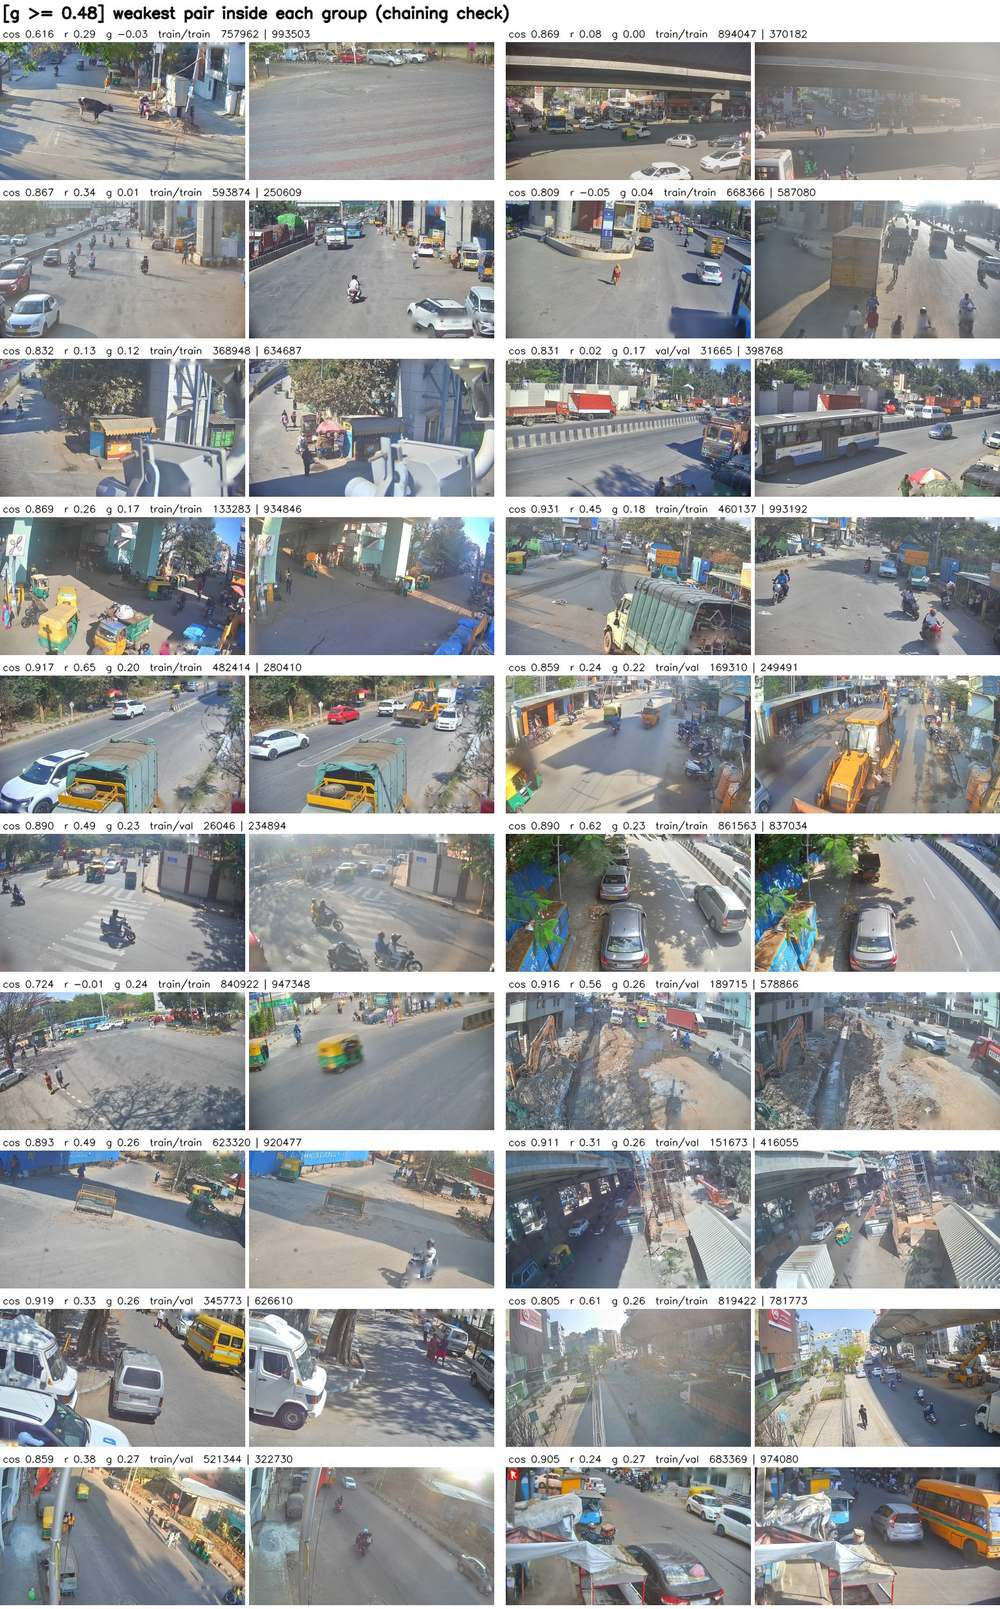

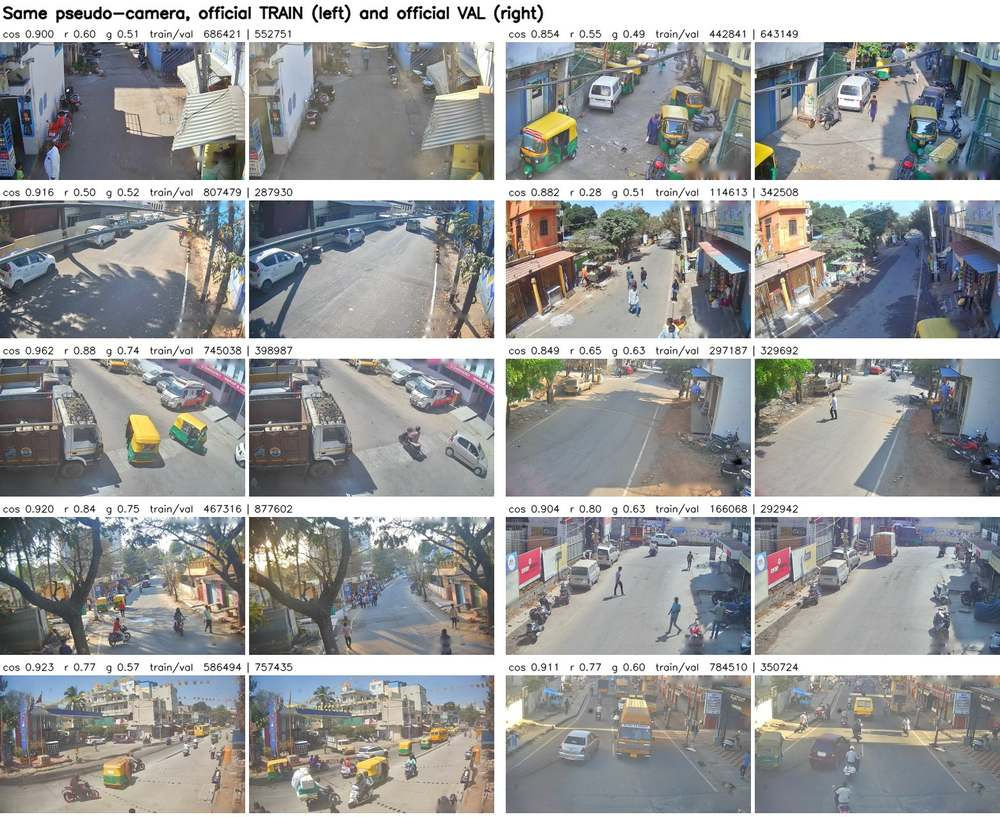

In [7]:
rule = cluster.Rule.from_config(cfg).name
for name, width in (("nn_gradient_g.png", 640), ("group_sizes.png", 640), (f"{rule}_above.jpg", 900),
                    (f"{rule}_below.jpg", 900), (f"{rule}_weakest_in_group.jpg", 900), ("leak_examples.jpg", 900)):
    if (FIGS / name).exists():  # a grid is skipped when no pair qualifies
        display(Image(filename=str(FIGS / name), width=width))

### Group split and class balance

In [8]:
if (cfg["paths"]["splits_dir"] / "test.sha256").exists():
    print("split is frozen; test.txt sha256 verified:", split.check_test_checksum(cfg))
    assignment = split.load(cfg)
else:
    assignment = split.make(cfg)
spl = split.summarise(cfg, assignment)
floor = cfg["split"]["min_test_instances"]
for k in ("images", "image_share", "pseudo_cameras", "official_split_composition",
          "classes_missing", f"classes_under_{floor}_test_instances"):
    print(f"{k}: {spl[k]}")
display(pd.read_csv(cfg["paths"]["results_dir"] / "split_class_counts.csv", header=[0, 1], index_col=0))

split is frozen; test.txt sha256 verified: f8181d247d7e034f5810b2bb2a978e2739e5055dbc8b3240877c5caa1f667ff6
images: {'train': 3071, 'val': 452, 'test': 477}
image_share: {'train': 0.7678, 'val': 0.113, 'test': 0.1192}
pseudo_cameras: {'train': 2318, 'val': 355, 'test': 410}
official_split_composition: {'train': {'train': 2477, 'val': 594}, 'val': {'train': 356, 'val': 96}, 'test': {'train': 368, 'val': 109}}
classes_missing: {'mv/val': [], 'mv/test': [], 'st/val': [], 'st/test': []}
classes_under_30_test_instances: {'mv': {'Mini-bus': 21, 'Tempo-traveller': 26, 'Others': 2}, 'st': {'Mini-bus': 25, 'Tempo-traveller': 28, 'Others': 3}}


mv                 st            
                 train   val  test  train   val  test
Hatchback         3463   615   586   3539   619   607
Sedan             1829   311   303   2159   379   356
SUV               1371   262   241   1803   347   300
MUV                666   141   131   1164   223   212
Bus               1053   221   148   1051   212   147
Truck             1624   269   247   2147   350   339
Three-wheeler     5916  1019   960   5840  1006   937
Two-wheeler      17780  3002  2846  17603  2981  2816
LCV               2047   285   343   2217   329   372
Mini-bus            91    18    21    138    18    25
Tempo-traveller    162    17    26    179    21    28
Bicycle            475    50    49    709    97    95
Van                230    41    48    270    44    62
Others              21     2     2     32     4     3

## 3. Preprocessing and augmentation

Each choice is an invariance I ask the model to learn. Values are Ultralytics 8.4 defaults unless stated (see the training arguments printed in Section 4).

| Choice | Invariance it asserts |
|---|---|
| Resize to 1280 px on the long side (JPEG q95), train at 960 px | Vehicle class is recognisable at half of 1080p resolution; 960 px keeps distant two-wheelers visible within the GPU budget |
| Horizontal flip, p = 0.5 | Vehicle type does not depend on left vs right. It mirrors India's left-hand traffic: fine for type, wrong for lane direction, which the task does not use |
| No vertical flip, no rotation (`flipud = 0`, `degrees = 0`) | A fixed CCTV camera is never upside down; these would teach impossible views |
| HSV jitter (hue 0.015, saturation 0.7, value 0.4) | Class is invariant to daylight changes between 06:00 and 18:00, haze and colour casts |
| Scale 0.5, translate 0.1, Mosaic (off for the last 10 epochs) | Class is invariant to distance from the camera and position in the frame |

## 4. Baseline: YOLOv8s fine-tuned on MV labels

### Context: COCO-pretrained YOLOv8s as-is
No fine-tuning. Predictions and labels are mapped to shared coarse classes (cars → car; Bus, Mini-bus → bus; Truck, LCV → truck; Two-wheeler → motorcycle; Bicycle → bicycle). Three-wheeler, Tempo-traveller, Van and Others have no COCO class and count as misses. This measures what COCO alone can do, and so why fine-tuning is needed (val only).

In [9]:
from src import evaluate, train

coco = evaluate.coco_context(cfg)
for ls in ("mv", "st"):
    m = coco[ls]
    print(f"{ls.upper()} labels: mAP50 {m['mAP50']:.3f}, mAP50-95 {m['mAP50_95']:.3f} over all coarse classes | "
          f"mappable only: mAP50 {m['mAP50_mappable_only']:.3f}, mAP50-95 {m['mAP50_95_mappable_only']:.3f}")
display(pd.DataFrame(coco["mv"]["per_class"]).T)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
MV labels: mAP50 0.274, mAP50-95 0.181 over all coarse classes | mappable only: mAP50 0.493, mAP50-95 0.326
ST labels: mAP50 0.243, mAP50-95 0.163 over all coarse classes | mappable only: mAP50 0.438, mAP50-95 0.294


,AP50,AP50_95,instances
car,0.8385,0.6679,1329.0
bus,0.5858,0.4594,239.0
truck,0.4803,0.3506,554.0
motorcycle,0.3768,0.1197,3002.0
bicycle,0.1827,0.0299,50.0
three-wheeler,0.0000,0.0000,1019.0
tempo-traveller,0.0000,0.0000,17.0
van,0.0000,0.0000,41.0
others,0.0000,0.0000,2.0


### Freeze pilot (val only)
YOLOv8s at 960 px, batch 8, seed 42, MV labels, `pilot_epochs` epochs per arm: backbone frozen (`freeze=10`) vs all layers trainable. I fixed the rule before running it: unfreeze the backbone only if it gains at least 0.02 mAP@0.50:0.95 on val, since freezing is cheaper. Runs are saved to Drive; re-running this cell resumes an interrupted arm and skips a finished one.

In [10]:
if RUN_TRAINING:
    for arm in ("frozen", "full"):
        train.ensure_run(cfg, "mv", pilot=arm)
pilot = train.pilot_summary(cfg)
display(pd.DataFrame({arm: {
    "val mAP50-95": s["val_last"]["mAP50_95"], "val mAP50": s["val_last"]["mAP50"],
    "minutes / epoch": s["minutes_per_epoch"], "first epoch (min)": s["minutes_first_epoch"],
    "total (min)": s["minutes_total"], f"epochs within {pilot['budget_minutes']} min": s["epochs_within_budget"],
} for arm, s in pilot["arms"].items()}))

pilot_frozen_mv: finished
pilot_full_mv: finished


,frozen,full
val mAP50-95,0.4054,0.4325
val mAP50,0.4946,0.5194
minutes / epoch,1.7200,1.8700
first epoch (min),1.7800,1.8800
total (min),8.6800,9.3800
epochs within 90 min,37.0000,34.0000


### Epoch budget
One full run must fit the 90-minute budget on a free T4, with the same epoch count for baseline and ablation. The pilot (5 epochs) ran entirely without mosaic, because Ultralytics switches mosaic off for the last `close_mosaic` = 10 epochs. A full run uses mosaic before that, and mosaic costs 1.35× per sample in the data pipeline (measured), so those epochs are budgeted as 1.35× slower (worst case: the run is data-bound). A 10% margin covers setup and the final validation. The chosen values are written to `configs/base.yaml` (`train.epochs`, `train.freeze`).

In [11]:
t = cfg["train"]
print(f"config: train.freeze = {t['freeze']}, train.epochs = {t['epochs']} "
      f"(close_mosaic {t['close_mosaic']}, mosaic cost x{t['mosaic_slowdown']}, budget {t['budget_minutes']} min)")
for arm, s in pilot["arms"].items():
    print(f"  {arm:6s}: freeze = {train.PILOTS[arm]}, {s['minutes_per_epoch']:.2f} min/epoch without mosaic -> "
          f"{s['epochs_within_budget']} epochs fit the budget (worst case); "
          f"{t['epochs']} epochs take at most {s['worst_case_minutes_at_config_epochs']} min")

config: train.freeze = None, train.epochs = 34 (close_mosaic 10, mosaic cost x1.35, budget 90 min)
  frozen: freeze = 10, 1.72 min/epoch without mosaic -> 37 epochs fit the budget (worst case); 34 epochs take at most 73.0 min
  full  : freeze = None, 1.87 min/epoch without mosaic -> 34 epochs fit the budget (worst case); 34 epochs take at most 79.3 min


### Baseline run
YOLOv8s, COCO weights, all layers trainable, 960 px, batch 8, seed 42, `train.epochs` epochs with early stopping (patience 10), MV labels. The ablation (Section 5) runs the same call with `"st"`; nothing else differs. The run is saved to Drive every epoch (`last.pt`) and every 5 epochs; re-running this cell after a disconnect resumes it.

mv: finished
{'epochs_run': 34, 'minutes_total': 65.44, 'minutes_per_epoch': 1.92}
val during training, best epoch: {'epoch': 34, 'precision': 0.6913, 'recall': 0.5524, 'mAP50': 0.6142, 'mAP50_95': 0.524}


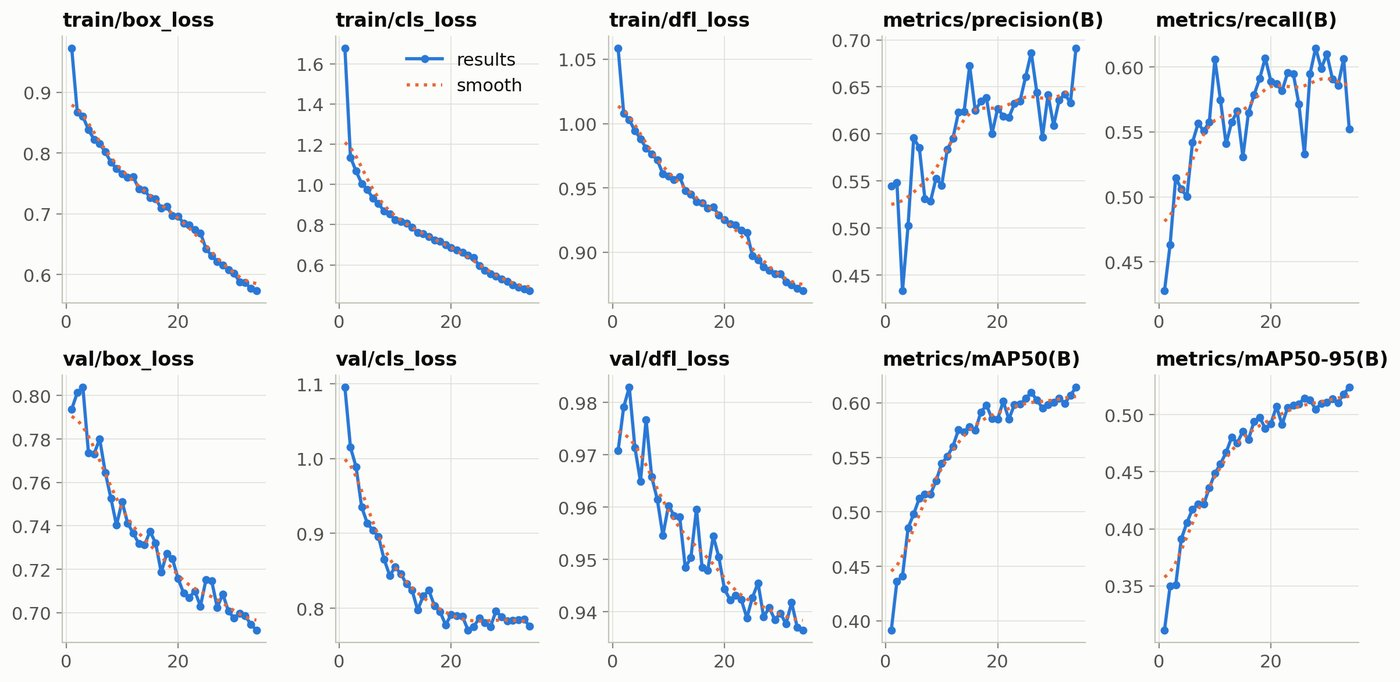

In [12]:
if RUN_TRAINING:
    baseline_dir = train.ensure_run(cfg, "mv")
else:
    baseline_dir = cfg["paths"]["runs_root"] / "mv"
baseline = train.run_summary(baseline_dir)
print({k: baseline[k] for k in ("epochs_run", "minutes_total", "minutes_per_epoch")})
print("val during training, best epoch:", baseline["val_best"])
display(Image(filename=str(baseline_dir / "results.png"), width=900))

### Generalisation gap
The baseline's best weights (`best.pt`, chosen on val mAP@0.50:0.95) scored on the train split and on val, MV labels, with identical settings (conf 0.001, NMS IoU 0.7, 960 px). Test stays sealed.

In [13]:
best = baseline_dir / "weights" / "best.pt"
gap = {s: evaluate.detector_metrics(cfg, best, "mv", s, name=f"mv__{s}__mv") for s in ("train", "val")}
overall = pd.DataFrame({s: {k: m[k] for k in ("mAP50", "mAP50_95", "precision", "recall")} for s, m in gap.items()})
display(overall.assign(gap=overall["train"] - overall["val"]).round(3))
per_class = pd.DataFrame({s: {c: v["AP50_95"] for c, v in m["per_class"].items()} for s, m in gap.items()})
per_class["val instances"] = pd.Series({c: v["instances"] for c, v in gap["val"]["per_class"].items()})
display(per_class.assign(gap=per_class["train"] - per_class["val"]).round(3).rename_axis("AP50-95"))

mv__train__mv: unchanged weights and settings, using the saved evaluation
mv__val__mv: unchanged weights and settings, using the saved evaluation


,train,val,gap
mAP50,0.914,0.614,0.300
mAP50_95,0.824,0.524,0.300
precision,0.873,0.692,0.181
recall,0.826,0.554,0.272


,train,val,val instances,gap
AP50-95,,,,
Hatchback,0.866,0.570,615,0.296
Sedan,0.874,0.557,311,0.318
SUV,0.862,0.477,262,0.385
MUV,0.842,0.411,141,0.431
Bus,0.889,0.702,221,0.187
Truck,0.863,0.569,269,0.294
Three-wheeler,0.885,0.782,1019,0.103
Two-wheeler,0.829,0.710,3002,0.119
LCV,0.864,0.578,285,0.286


### Fine-tuning gain, like for like
The baseline's 14-class predictions mapped to the same coarse classes as the COCO-as-is run (cars → car, Bus/Mini-bus → bus, Truck/LCV → truck, …; NMS re-run per coarse class), scored with the same matching on val. This is the fair comparison with the COCO context number above.

In [14]:
fine = evaluate.finetuned_coarse(cfg, best, "mv")
rows = {"mAP50-95, all 9 coarse classes": "mAP50_95", "mAP50-95, 5 COCO-mappable": "mAP50_95_mappable_only",
        "mAP50, all 9 coarse classes": "mAP50", "mAP50, 5 COCO-mappable": "mAP50_mappable_only"}
display(pd.DataFrame({"COCO as-is": {r: coco["mv"][k] for r, k in rows.items()},
                      "fine-tuned on MV": {r: fine["mv"][k] for r, k in rows.items()}}).round(3))
display(pd.DataFrame({"COCO as-is": {c: v["AP50_95"] for c, v in coco["mv"]["per_class"].items()},
                      "fine-tuned on MV": {c: v["AP50_95"] for c, v in fine["mv"]["per_class"].items()}}).round(3).rename_axis("AP50-95"))

,COCO as-is,fine-tuned on MV
"mAP50-95, all 9 coarse classes",0.181,0.552
"mAP50-95, 5 COCO-mappable",0.326,0.663
"mAP50, all 9 coarse classes",0.274,0.659
"mAP50, 5 COCO-mappable",0.493,0.805


,COCO as-is,fine-tuned on MV
AP50-95,,
car,0.668,0.802
bus,0.459,0.663
truck,0.351,0.632
motorcycle,0.120,0.707
bicycle,0.030,0.511
three-wheeler,0.000,0.773
tempo-traveller,0.000,0.638
van,0.000,0.247
others,0.000,0.000


## 5. Ablation: MV vs STAPLE training labels

The crowd annotations were merged two ways: majority voting (MV) and STAPLE (ST, an expectation-maximisation consensus). The two disagree (STAPLE has 6% more boxes on the same images), so I ask whether the merging method changes what the detector learns. The ablation trains a second model **identical to the baseline except for the training labels**: same config file, seed 42, 34 epochs, all layers trainable, 960 px, same train and val images. Only `train.ensure_run(cfg, "st")` differs from the baseline call.

st: finished
{'epochs_run': 34, 'minutes_total': 66.31, 'minutes_per_epoch': 1.94}
val during training (ST labels), best epoch: {'epoch': 25, 'precision': 0.6429, 'recall': 0.5772, 'mAP50': 0.5844, 'mAP50_95': 0.494}


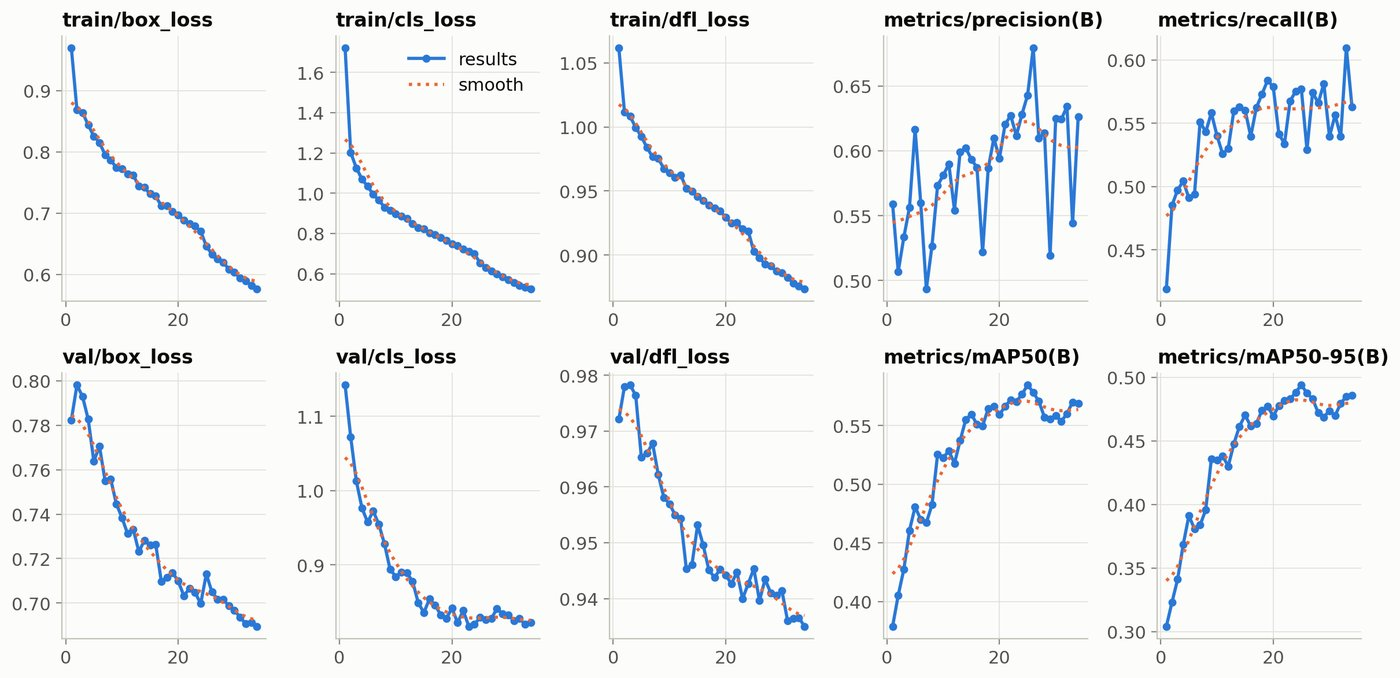

In [15]:
if RUN_TRAINING:
    ablation_dir = train.ensure_run(cfg, "st")
else:
    ablation_dir = cfg["paths"]["runs_root"] / "st"
ablation = train.run_summary(ablation_dir)
print({k: ablation[k] for k in ("epochs_run", "minutes_total", "minutes_per_epoch")})
print("val during training (ST labels), best epoch:", ablation["val_best"])
display(Image(filename=str(ablation_dir / "results.png"), width=900))

### Proof of control
Every training setting of the two runs, compared from the settings stored in each run's checkpoint (after Ultralytics resolves `auto` values). Only the data yaml, i.e. the label set, may differ, plus run bookkeeping (name, output folder, resume paths). The raw `args.yaml` diff is saved too; a resumed run rewrites `args.yaml` with resolved values, so the checkpoint settings are the reliable record.

In [16]:
ctrl = train.args_diff(cfg, "mv", "st")
display(pd.DataFrame(ctrl["effective_differing_keys"], index=["MV run", "STAPLE run"]).T)
print("label-set keys:", ctrl["label_set_keys"], "| bookkeeping:", ctrl["bookkeeping_keys"], "| unexpected:", ctrl["unexpected_keys"])
print("same train / val images:", ctrl["same_images"], "| resumed:", ctrl["resumed"])
print("ONLY DIFFERENCE IS THE LABEL SET:", ctrl["only_difference_is_label_set"])

,MV run,STAPLE run
data,/content/datasets/uvh26_mv.yaml,/content/datasets/uvh26_st.yaml
name,mv,st


label-set keys: ['data'] | bookkeeping: ['name'] | unexpected: []
same train / val images: {'train': True, 'val': True} | resumed: {'mv': False, 'st': False}
ONLY DIFFERENCE IS THE LABEL SET: True


### 2 × 2: trained-on × scored-against (val)
Scoring each model only against its own label style is biased: a box one consensus keeps and the other drops counts as a miss or a false positive depending on the labels used. Each model is therefore scored against both MV and STAPLE val labels. Compare models **within a column** (same labels).

In [17]:
runs = {"mv": baseline_dir, "st": ablation_dir}
cells = {(tr, sc): evaluate.detector_metrics(cfg, runs[tr] / "weights" / "best.pt", sc, "val", name=f"{tr}__val__{sc}")
         for tr in ("mv", "st") for sc in ("mv", "st")}
for metric in ("mAP50_95", "mAP50", "precision", "recall"):
    print(metric)
    display(pd.DataFrame({f"scored vs {sc.upper()} labels": {f"trained on {tr.upper()}": cells[(tr, sc)][metric]
                                                              for tr in ("mv", "st")} for sc in ("mv", "st")}))
per = pd.DataFrame({f"{tr.upper()}-trained vs {sc.upper()}": {c: v["AP50_95"] for c, v in cells[(tr, sc)]["per_class"].items()}
                    for tr, sc in cells})
per["val instances (MV)"] = pd.Series({c: v["instances"] for c, v in cells[("mv", "mv")]["per_class"].items()})
display(per.round(3).rename_axis("AP50-95"))

mv__val__mv: unchanged weights and settings, using the saved evaluation
mv__val__st: unchanged weights and settings, using the saved evaluation
st__val__mv: unchanged weights and settings, using the saved evaluation
st__val__st: unchanged weights and settings, using the saved evaluation
mAP50_95


,scored vs MV labels,scored vs ST labels
trained on MV,0.5245,0.4923
trained on ST,0.5131,0.4948


mAP50


,scored vs MV labels,scored vs ST labels
trained on MV,0.6145,0.5779
trained on ST,0.6107,0.5850


precision


,scored vs MV labels,scored vs ST labels
trained on MV,0.6919,0.6280
trained on ST,0.5203,0.6428


recall


,scored vs MV labels,scored vs ST labels
trained on MV,0.5538,0.5778
trained on ST,0.6506,0.5761


,MV-trained vs MV,MV-trained vs ST,ST-trained vs MV,ST-trained vs ST,val instances (MV)
AP50-95,,,,,
Hatchback,0.570,0.572,0.543,0.533,615
Sedan,0.557,0.582,0.525,0.564,311
SUV,0.477,0.512,0.514,0.534,262
MUV,0.411,0.394,0.345,0.361,141
Bus,0.702,0.702,0.697,0.700,221
Truck,0.569,0.504,0.550,0.504,269
Three-wheeler,0.782,0.788,0.779,0.783,1019
Two-wheeler,0.710,0.706,0.696,0.693,3002
LCV,0.578,0.539,0.566,0.531,285


### Is the difference larger than evaluation noise?
Paired bootstrap over val images: the same resampled image sets are scored for both models, giving a 95% interval for (STAPLE-trained − MV-trained) in each column. This measures evaluation-set sampling noise only; seed-to-seed training noise would need a second pair of runs.

In [18]:
boot = {sc: evaluate.paired_bootstrap(cfg, f"mv__val__{sc}", f"st__val__{sc}", n_boot=cfg["evaluate"]["n_boot"])
        for sc in ("mv", "st")}
display(pd.DataFrame({f"scored vs {sc.upper()} labels": {
    "MV-trained mAP50-95": b["a_mAP50_95"], "ST-trained mAP50-95": b["b_mAP50_95"],
    "ST - MV, mAP50-95": b["diff_mAP50_95"], "95% CI": b["diff_mAP50_95_ci95"],
    "ST - MV, mAP50": b["diff_mAP50"], "95% CI ": b["diff_mAP50_ci95"],
    "resamples where ST better (mAP50-95)": b["share_b_better_mAP50_95"],
} for sc, b in boot.items()}))

,scored vs MV labels,scored vs ST labels
MV-trained mAP50-95,0.5245,0.4923
ST-trained mAP50-95,0.5131,0.4948
"ST - MV, mAP50-95",-0.0114,0.0025
95% CI,"[-0.0304, 0.0135]","[-0.0131, 0.024]"
"ST - MV, mAP50",-0.0038,0.0071
95% CI,"[-0.0274, 0.0347]","[-0.0101, 0.03]"
resamples where ST better (mAP50-95),0.218,0.62


### Which classes move?
Per-class AP@0.50:0.95 difference (STAPLE-trained − MV-trained) with 95% intervals from the same paired bootstrap, in each column. Classes with fewer than about 30 val instances (Mini-bus, Tempo-traveller, Others) are too small to read.

In [19]:
per_cls = {}
for sc in ("st", "mv"):
    for c, v in boot[sc]["per_class_AP50_95"].items():
        per_cls.setdefault(c, {})[f"ST - MV vs {sc.upper()}"] = v["diff"]
        per_cls[c][f"95% CI vs {sc.upper()}"] = v["ci95"]
per_cls = pd.DataFrame(per_cls).T
per_cls["val instances (ST)"] = pd.Series({c: v["instances"] for c, v in cells[("st", "st")]["per_class"].items()})
display(per_cls.rename_axis("AP50-95"))

,ST - MV vs ST,95% CI vs ST,ST - MV vs MV,95% CI vs MV,val instances (ST)
AP50-95,,,,,
Hatchback,-0.0393,"[-0.0646, -0.0093]",-0.0276,"[-0.0569, 0.0031]",619
Sedan,-0.0181,"[-0.0504, 0.0149]",-0.0315,"[-0.0615, 0.004]",379
SUV,0.0212,"[-0.0106, 0.0576]",0.0366,"[-0.0063, 0.0808]",347
MUV,-0.033,"[-0.0759, 0.0224]",-0.0657,"[-0.1207, 0.0196]",223
Bus,-0.0027,"[-0.0272, 0.0207]",-0.0048,"[-0.026, 0.0198]",212
Truck,-0.0001,"[-0.0315, 0.032]",-0.0191,"[-0.054, 0.0195]",350
Three-wheeler,-0.0052,"[-0.013, 0.0033]",-0.0031,"[-0.0107, 0.0059]",1006
Two-wheeler,-0.0124,"[-0.0174, -0.0077]",-0.0133,"[-0.0184, -0.0086]",2981
LCV,-0.0084,"[-0.0389, 0.0246]",-0.0122,"[-0.0424, 0.0231]",329


### Robustness: last-epoch weights
Each run keeps the checkpoint with the best val mAP against its *own* labels: the MV run picked epoch 34 (its last), the STAPLE run epoch 25. Choosing on the scoring labels slightly favours the STAPLE model in the STAPLE column. Scoring both models' epoch-34 weights (`last.pt`, no selection) removes that asymmetry.

In [20]:
last = {(tr, sc): evaluate.detector_metrics(cfg, runs[tr] / "weights" / "last.pt", sc, "val", name=f"{tr}_last__val__{sc}")
        for tr in ("mv", "st") for sc in ("mv", "st")}
boot_last = {sc: evaluate.paired_bootstrap(cfg, f"mv_last__val__{sc}", f"st_last__val__{sc}", n_boot=cfg["evaluate"]["n_boot"])
             for sc in ("mv", "st")}
display(pd.DataFrame({f"scored vs {sc.upper()} labels": {
    "MV-trained, epoch 34": b["a_mAP50_95"], "ST-trained, epoch 34": b["b_mAP50_95"],
    "ST - MV, mAP50-95": b["diff_mAP50_95"], "95% CI": b["diff_mAP50_95_ci95"],
} for sc, b in boot_last.items()}))

mv_last__val__mv: unchanged weights and settings, using the saved evaluation
mv_last__val__st: unchanged weights and settings, using the saved evaluation
st_last__val__mv: unchanged weights and settings, using the saved evaluation
st_last__val__st: unchanged weights and settings, using the saved evaluation


,scored vs MV labels,scored vs ST labels
"MV-trained, epoch 34",0.5245,0.4923
"ST-trained, epoch 34",0.5101,0.4869
"ST - MV, mAP50-95",-0.0144,-0.0053
95% CI,"[-0.0319, 0.0112]","[-0.0213, 0.0186]"


## 6. Evaluation: threshold chosen on val, test opened once

### From detections to Passenger Car Units (val only)
Green time is allocated by demand in PCU, so each detected vehicle is weighted by its IRC:106-1990 equivalency factor. IRC gives a factor at 5% and at 10%-and-above share of the traffic stream; the shares come from the training split's STAPLE labels, and factors are interpolated linearly in between. All four car body types and vans weigh 1.0 PCU, so confusing a Hatchback with an SUV costs nothing here; confusing a Truck (3.28) with an LCV (1.54) does.

In [21]:
from src import counts

fac = counts.pcu_factors(cfg)
display(pd.DataFrame({"IRC category": fac["class_category"], "PCU factor": fac["class_factor"]})
        .assign(**{"category share of train traffic (%)": lambda d: d["IRC category"].map(fac["category_share_pct"])}))

,IRC category,PCU factor,category share of train traffic (%)
Hatchback,car,1.0000,23.00
Sedan,car,1.0000,23.00
SUV,car,1.0000,23.00
MUV,car,1.0000,23.00
Van,car,1.0000,23.00
Bus,truck_bus,3.2760,8.59
Truck,truck_bus,3.2760,8.59
Mini-bus,truck_bus,3.2760,8.59
Tempo-traveller,lcv,1.5401,6.17
LCV,lcv,1.5401,6.17


### Operating threshold
Counting uses one box per vehicle: each box keeps its top class and NMS is class-agnostic (the mAP evaluation keeps several labels per box, which would count one vehicle more than once). For each model, the confidence threshold is swept from 0.05 to 0.70 on val and the value with the lowest mean absolute PCU error per image is chosen, against STAPLE labels (the headline label set). The chosen values are then frozen in `configs/base.yaml` (`evaluate.conf`) before the test set is opened.

val: 452 images, mean true demand 18.482 PCU per image (ST labels)


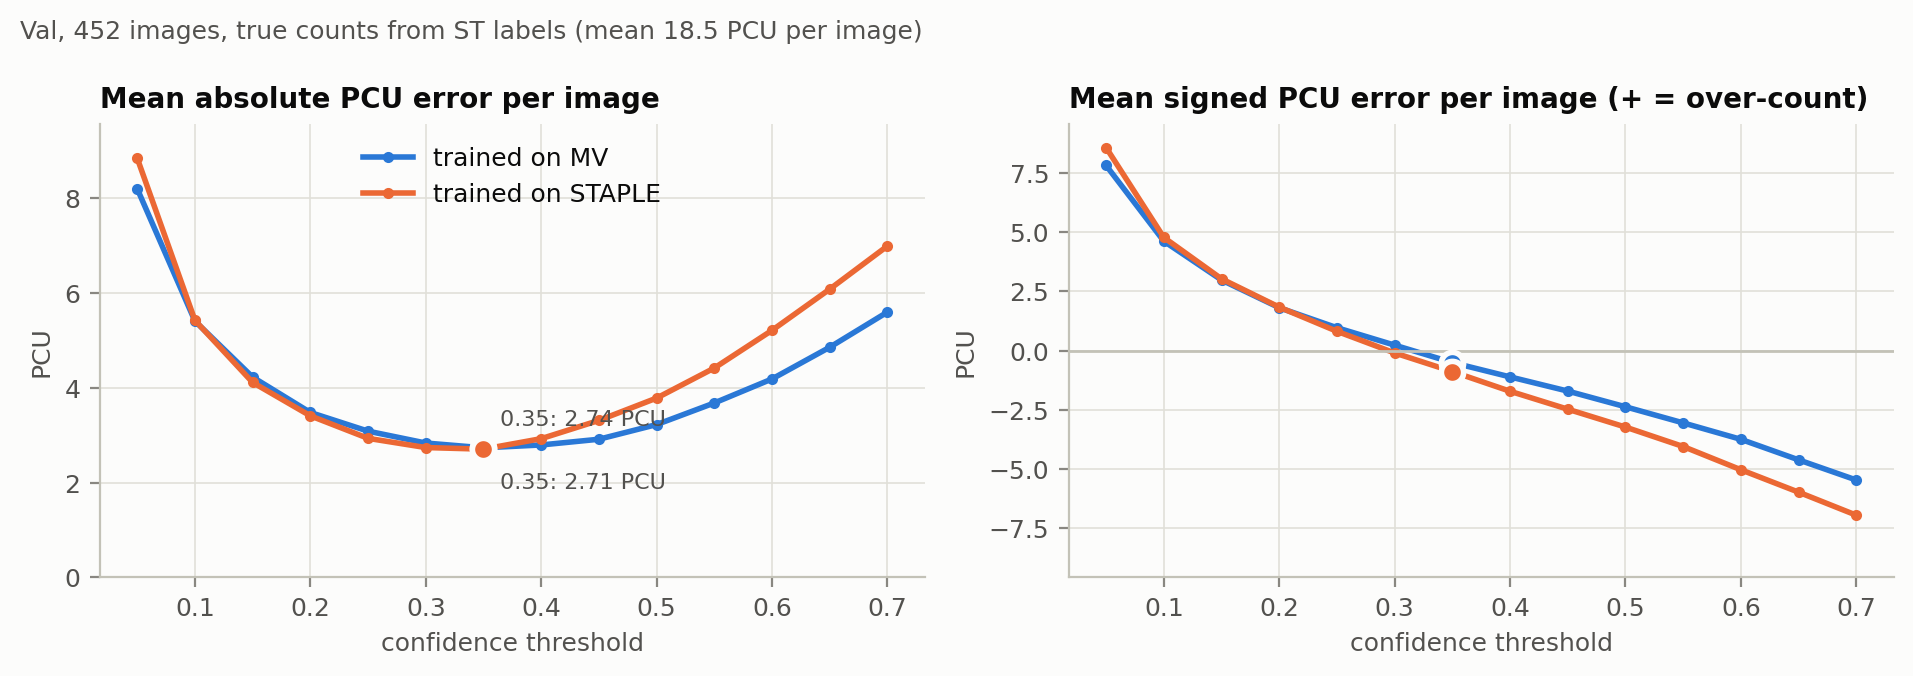

,trained on MV,trained on ST
chosen threshold,0.3500,0.3500
frozen in config,0.3500,0.3500
pcu_mae vs ST,2.7358,2.7081
pcu_bias vs ST,-0.5025,-0.8830
pcu_rel_mae vs ST,0.1480,0.1465
count_mae vs ST,1.9004,1.9690
count_bias vs ST,-0.0288,-0.3230
pcu_mae vs MV,2.3510,2.2559
pcu_bias vs MV,0.6853,0.3047
pcu_rel_mae vs MV,0.1359,0.1304


MV-trained model at threshold 0.35: per-class counts vs ST labels


,true per image,count MAE,signed bias,true total,predicted total
Hatchback,1.369,0.715,-0.011,619.0,614.0
Sedan,0.838,0.407,-0.093,379.0,337.0
SUV,0.768,0.507,-0.175,347.0,268.0
MUV,0.493,0.367,-0.239,223.0,115.0
Bus,0.469,0.179,0.024,212.0,223.0
Truck,0.774,0.471,-0.228,350.0,247.0
Three-wheeler,2.226,0.456,0.150,1006.0,1074.0
Two-wheeler,6.595,1.310,0.686,2981.0,3291.0
LCV,0.728,0.425,0.013,329.0,335.0
Mini-bus,0.040,0.031,-0.022,18.0,8.0


ST-trained model at threshold 0.35: per-class counts vs ST labels


,true per image,count MAE,signed bias,true total,predicted total
Hatchback,1.369,0.728,-0.215,619.0,522.0
Sedan,0.838,0.409,-0.122,379.0,324.0
SUV,0.768,0.447,-0.009,347.0,343.0
MUV,0.493,0.376,-0.252,223.0,109.0
Bus,0.469,0.190,0.004,212.0,214.0
Truck,0.774,0.427,-0.192,350.0,263.0
Three-wheeler,2.226,0.414,0.060,1006.0,1033.0
Two-wheeler,6.595,1.314,0.597,2981.0,3251.0
LCV,0.728,0.394,-0.035,329.0,313.0
Mini-bus,0.040,0.029,-0.029,18.0,5.0


In [22]:
cnt = counts.run(cfg)
ref = cnt["reference_labels"].upper()
print(f"val: {cnt['images']} images, mean true demand {cnt['true_pcu_per_image_mean']} PCU per image ({ref} labels)")
display(Image(filename=str(FIGS / "pcu_threshold_sweep_val.png"), width=900))
display(pd.DataFrame({f"trained on {m.upper()}": {
    "chosen threshold": r["chosen_threshold"], "frozen in config": r["frozen_conf"],
    **{f"{k} vs {ls.upper()}": v for ls in ("st", "mv") for k, v in r["at_threshold"][ls].items()},
} for m, r in cnt["models"].items()}))
for m, r in cnt["models"].items():
    print(f"{m.upper()}-trained model at threshold {r['chosen_threshold']}: per-class counts vs {ref} labels")
    display(pd.DataFrame(r["per_class_vs_reference"]).T)

### Sealed test set (evaluated once)
Every choice above was made on val: freeze setting, epoch count, checkpoint (best val mAP) and the counting thresholds frozen in `evaluate.conf`. The test split (477 images from pseudo-cameras never used for training or selection) is opened only after that, by setting `EVALUATE_TEST = True` in the first cell. The cell first checks the test list against the checksum stored when the split was frozen. Nothing is tuned after this point, and later runs reload the saved test evaluation rather than re-scoring.

In [23]:
if not EVALUATE_TEST:
    print("EVALUATE_TEST = False: the sealed test set stays closed.")
else:
    conf = cfg["evaluate"]["conf"]
    assert all(v is not None for v in conf.values()), "freeze evaluate.conf on val before opening the test set"
    print("test.txt sha256 verified:", split.check_test_checksum(cfg), "| frozen thresholds:", conf)
    test_cells = {(tr, sc): evaluate.detector_metrics(cfg, runs[tr] / "weights" / "best.pt", sc, "test",
                                                      name=f"{tr}__test__{sc}", allow_test=True)
                  for tr in ("mv", "st") for sc in ("mv", "st")}
    for metric in ("mAP50_95", "mAP50", "precision", "recall"):
        print("TEST", metric)
        display(pd.DataFrame({f"scored vs {sc.upper()} labels": {f"trained on {tr.upper()}": test_cells[(tr, sc)][metric]
                                                                  for tr in ("mv", "st")} for sc in ("mv", "st")}))
    boot_test = {sc: evaluate.paired_bootstrap(cfg, f"mv__test__{sc}", f"st__test__{sc}", n_boot=cfg["evaluate"]["n_boot"])
                 for sc in ("mv", "st")}
    display(pd.DataFrame({f"TEST, scored vs {sc.upper()} labels": {
        "MV-trained mAP50-95": b["a_mAP50_95"], "ST-trained mAP50-95": b["b_mAP50_95"],
        "ST - MV, mAP50-95": b["diff_mAP50_95"], "95% CI": b["diff_mAP50_95_ci95"],
        "ST - MV, mAP50": b["diff_mAP50"], "95% CI ": b["diff_mAP50_ci95"],
    } for sc, b in boot_test.items()}))
    per_test = pd.DataFrame({f"{tr.upper()}-trained vs {sc.upper()}": {c: v["AP50_95"] for c, v in test_cells[(tr, sc)]["per_class"].items()}
                             for tr, sc in test_cells})
    per_test["test instances (ST)"] = pd.Series({c: v["instances"] for c, v in test_cells[("st", "st")]["per_class"].items()})
    display(per_test.round(3).rename_axis("TEST AP50-95"))

test.txt sha256 verified: f8181d247d7e034f5810b2bb2a978e2739e5055dbc8b3240877c5caa1f667ff6 | frozen thresholds: {'mv': 0.35, 'st': 0.35}
mv__test__mv: unchanged weights and settings, using the saved evaluation
mv__test__st: unchanged weights and settings, using the saved evaluation
st__test__mv: unchanged weights and settings, using the saved evaluation
st__test__st: unchanged weights and settings, using the saved evaluation
TEST mAP50_95


,scored vs MV labels,scored vs ST labels
trained on MV,0.4892,0.4550
trained on ST,0.4750,0.4482


TEST mAP50


,scored vs MV labels,scored vs ST labels
trained on MV,0.5710,0.5324
trained on ST,0.5545,0.5277


TEST precision


,scored vs MV labels,scored vs ST labels
trained on MV,0.6156,0.6090
trained on ST,0.5997,0.6167


TEST recall


,scored vs MV labels,scored vs ST labels
trained on MV,0.5619,0.5137
trained on ST,0.5510,0.5045


,"TEST, scored vs MV labels","TEST, scored vs ST labels"
MV-trained mAP50-95,0.4892,0.455
ST-trained mAP50-95,0.475,0.4482
"ST - MV, mAP50-95",-0.0141,-0.0068
95% CI,"[-0.035, 0.0105]","[-0.0226, 0.0078]"
"ST - MV, mAP50",-0.0165,-0.0047
95% CI,"[-0.0378, 0.0114]","[-0.0246, 0.0125]"


,MV-trained vs MV,MV-trained vs ST,ST-trained vs MV,ST-trained vs ST,test instances (ST)
TEST AP50-95,,,,,
Hatchback,0.579,0.579,0.556,0.566,607
Sedan,0.587,0.596,0.578,0.586,356
SUV,0.439,0.450,0.430,0.483,300
MUV,0.385,0.352,0.352,0.349,212
Bus,0.654,0.661,0.650,0.641,147
Truck,0.554,0.462,0.515,0.464,339
Three-wheeler,0.798,0.800,0.794,0.796,937
Two-wheeler,0.734,0.727,0.714,0.710,2816
LCV,0.587,0.552,0.571,0.551,372


#### Generalisation: train, val and test
Each model scored against its own label set on the three splits. Train is the data it was fitted on; val chose its checkpoint and thresholds; test is unseen cameras touched once.

In [24]:
if EVALUATE_TEST:
    gen = {}
    for m in ("mv", "st"):
        tr = evaluate.detector_metrics(cfg, runs[m] / "weights" / "best.pt", m, "train", name=f"{m}__train__{m}")
        gen[f"trained and scored on {m.upper()}"] = {"train": tr["mAP50_95"], "val": cells[(m, m)]["mAP50_95"],
                                                     "test": test_cells[(m, m)]["mAP50_95"]}
    gen = pd.DataFrame(gen).T
    display(gen.assign(**{"train - test": gen["train"] - gen["test"], "val - test": gen["val"] - gen["test"]}).round(3)
            .rename_axis("mAP50-95"))

mv__train__mv: unchanged weights and settings, using the saved evaluation
st__train__st: unchanged weights and settings, using the saved evaluation


,train,val,test,train - test,val - test
mAP50-95,,,,,
trained and scored on MV,0.824,0.524,0.489,0.335,0.035
trained and scored on ST,0.660,0.495,0.448,0.212,0.047


#### Counts and PCU at the frozen thresholds
The decision metric: per-image vehicle counts and PCU totals on test, with the thresholds frozen on val, against STAPLE labels (headline) and MV labels.

In [25]:
if EVALUATE_TEST:
    cnt_test = counts.evaluate_frozen(cfg, "test", allow_test=True)
    print("test: mean true demand per image (PCU):", cnt_test["true_pcu_per_image_mean"])
    display(pd.DataFrame({f"trained on {m.upper()} @ {r['threshold']}": {
        f"{k} vs {ls.upper()}": v for ls in ("st", "mv") for k, v in r["errors"][ls].items()
    } for m, r in cnt_test["models"].items()}))
    for m, r in cnt_test["models"].items():
        print(f"TEST, {m.upper()}-trained at {r['threshold']}: per-class counts vs {cnt_test['reference_labels'].upper()} labels")
        display(pd.DataFrame(r["per_class_vs_reference"]).T)

test: mean true demand per image (PCU): {'mv': 15.351, 'st': 16.484}


,trained on MV @ 0.35,trained on ST @ 0.35
pcu_mae vs ST,2.6092,2.7002
pcu_bias vs ST,-0.9349,-1.2521
pcu_rel_mae vs ST,0.1583,0.1638
count_mae vs ST,1.7526,1.8050
count_bias vs ST,-0.4990,-0.7107
pcu_mae vs MV,2.2943,2.2904
pcu_bias vs MV,0.1990,-0.1182
pcu_rel_mae vs MV,0.1495,0.1492
count_mae vs MV,1.5849,1.5702
count_bias vs MV,0.2306,0.0189


TEST, MV-trained at 0.35: per-class counts vs ST labels


,true per image,count MAE,signed bias,true total,predicted total
Hatchback,1.273,0.623,0.048,607.0,630.0
Sedan,0.746,0.417,-0.115,356.0,301.0
SUV,0.629,0.405,-0.166,300.0,221.0
MUV,0.444,0.321,-0.187,212.0,123.0
Bus,0.308,0.149,-0.031,147.0,132.0
Truck,0.711,0.440,-0.168,339.0,259.0
Three-wheeler,1.964,0.390,0.067,937.0,969.0
Two-wheeler,5.904,0.981,0.222,2816.0,2922.0
LCV,0.780,0.478,0.071,372.0,406.0
Mini-bus,0.052,0.052,-0.036,25.0,8.0


TEST, ST-trained at 0.35: per-class counts vs ST labels


,true per image,count MAE,signed bias,true total,predicted total
Hatchback,1.273,0.667,-0.159,607.0,531.0
Sedan,0.746,0.423,-0.155,356.0,282.0
SUV,0.629,0.430,0.010,300.0,305.0
MUV,0.444,0.342,-0.191,212.0,121.0
Bus,0.308,0.136,-0.027,147.0,134.0
Truck,0.711,0.398,-0.159,339.0,263.0
Three-wheeler,1.964,0.369,0.021,937.0,947.0
Two-wheeler,5.904,0.979,0.216,2816.0,2919.0
LCV,0.780,0.392,-0.031,372.0,357.0
Mini-bus,0.052,0.050,-0.042,25.0,5.0


#### Report figures: precision-recall and confusion
Precision-recall at IoU 0.5 (mean over classes) for both models on test, against STAPLE labels. The confusion matrices come from the counting pipeline as deployed: one box per vehicle at the frozen threshold, matched to labels at IoU ≥ 0.5 regardless of class. Rows are labelled classes (shares sum to 1 with the "missed" column); the bottom row counts predictions with no labelled vehicle. Ultralytics' own confusion matrix is not used: it is built from the mAP predictions (confidence ≥ 0.001, several class labels per box, ties broken arbitrarily), which overstates confusion between similar classes. The IRC-category version is the one that matters for PCU: confusions inside "car" cost nothing.

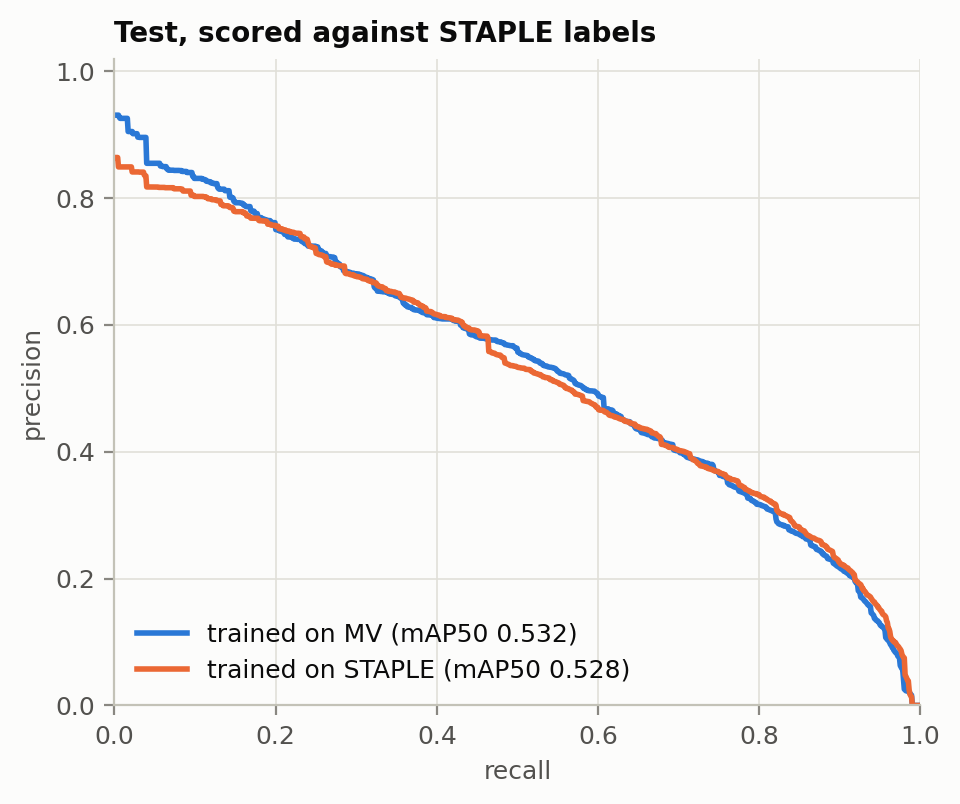

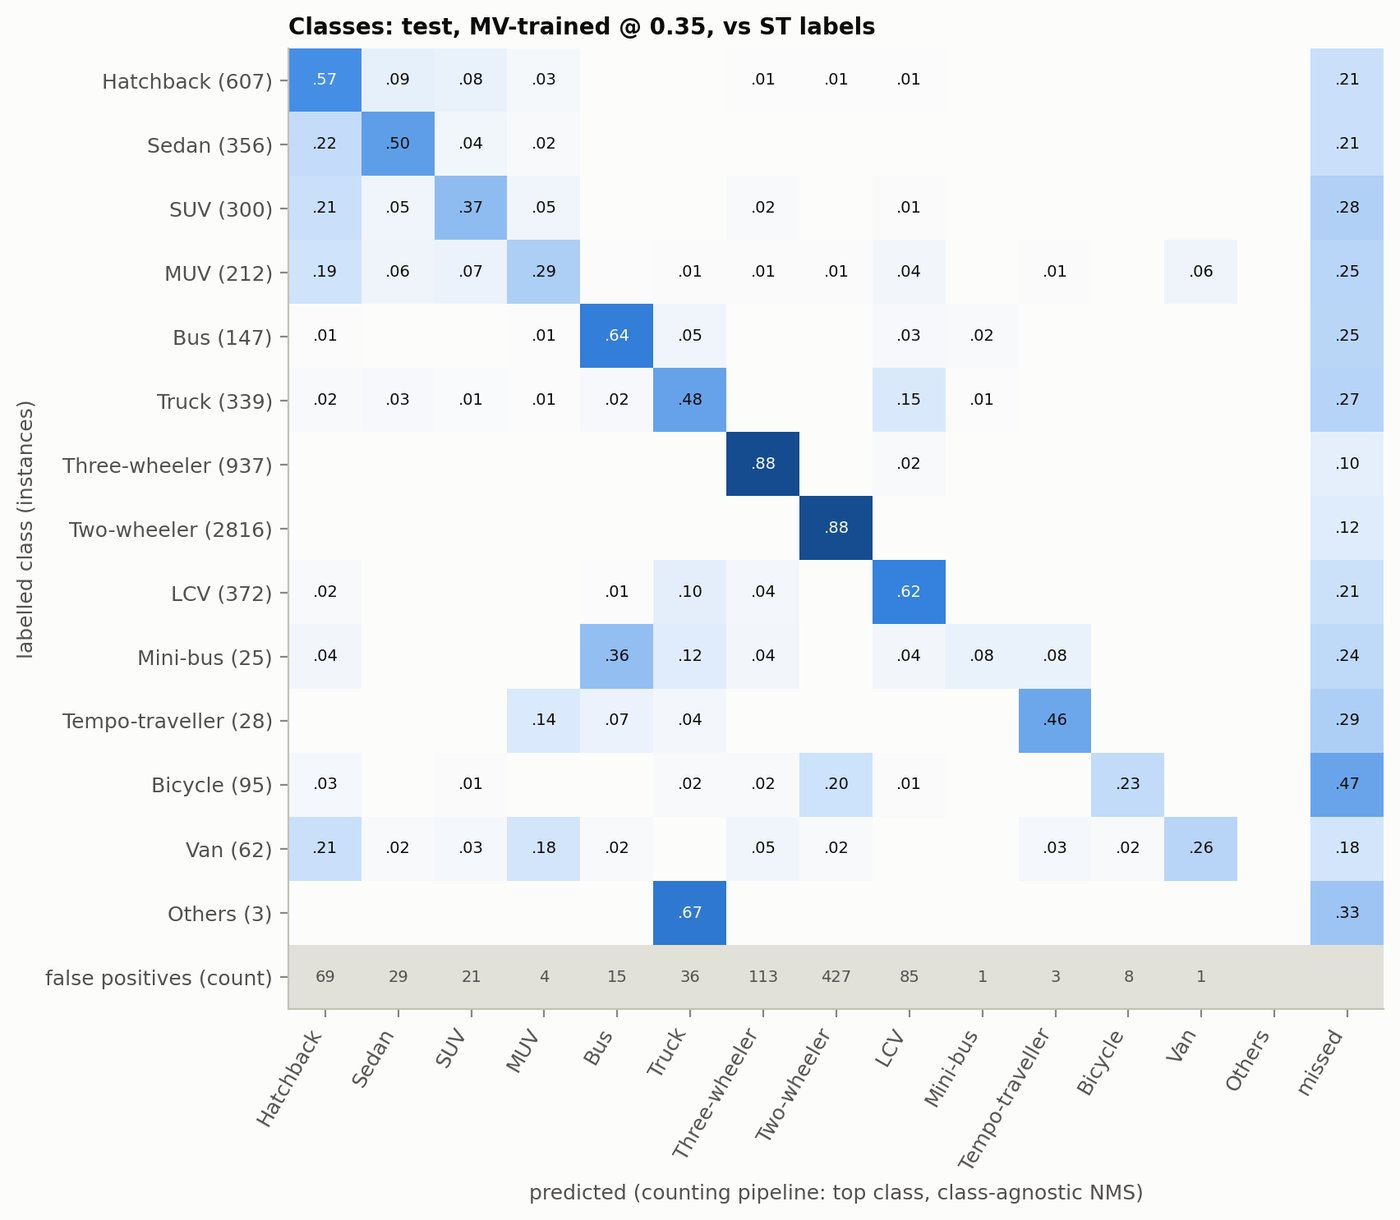

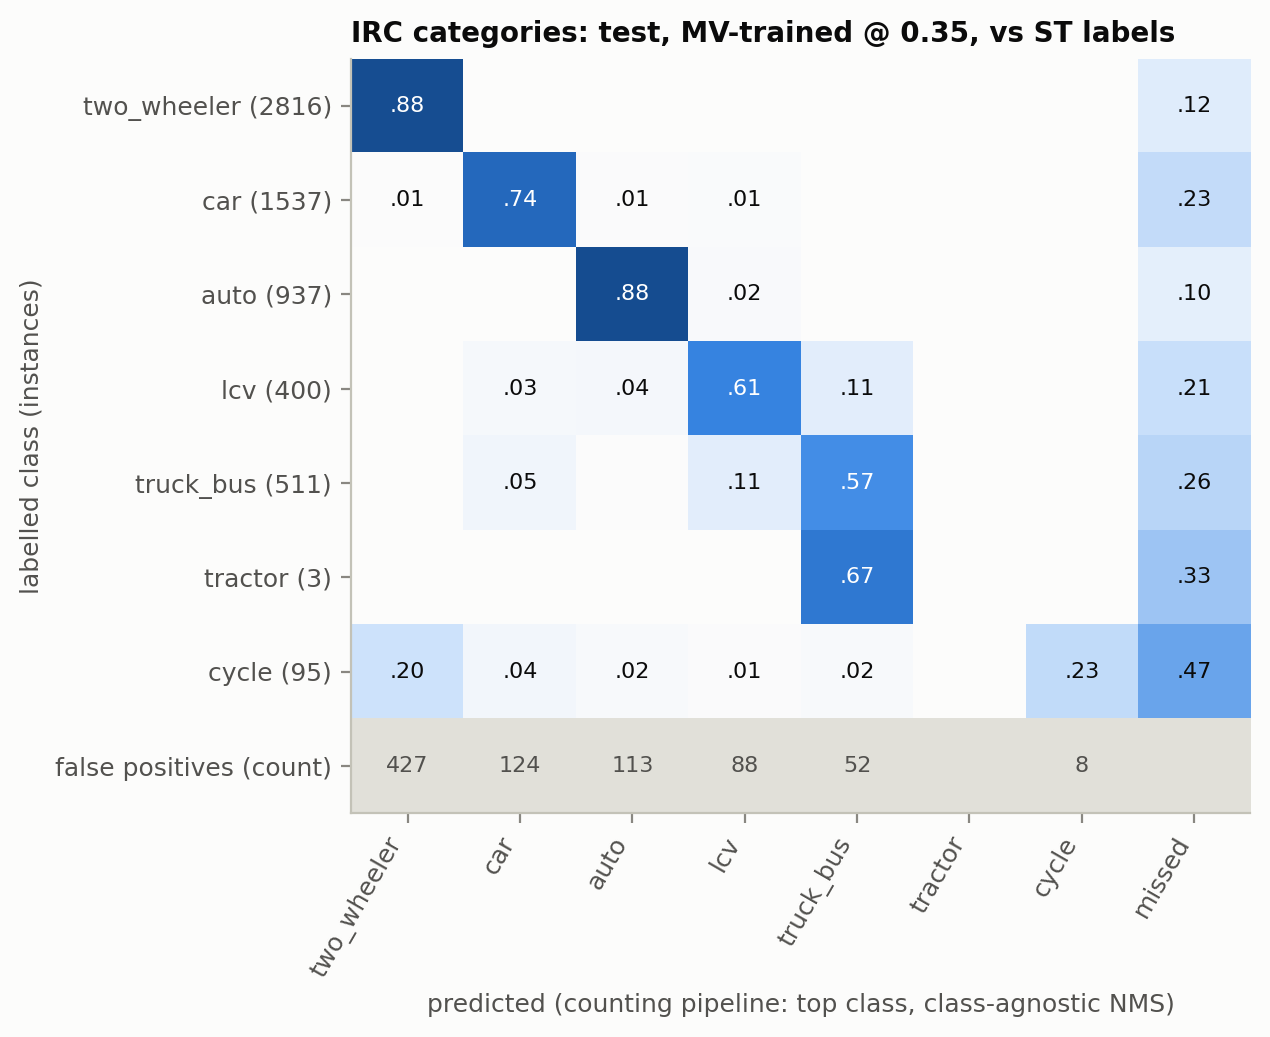

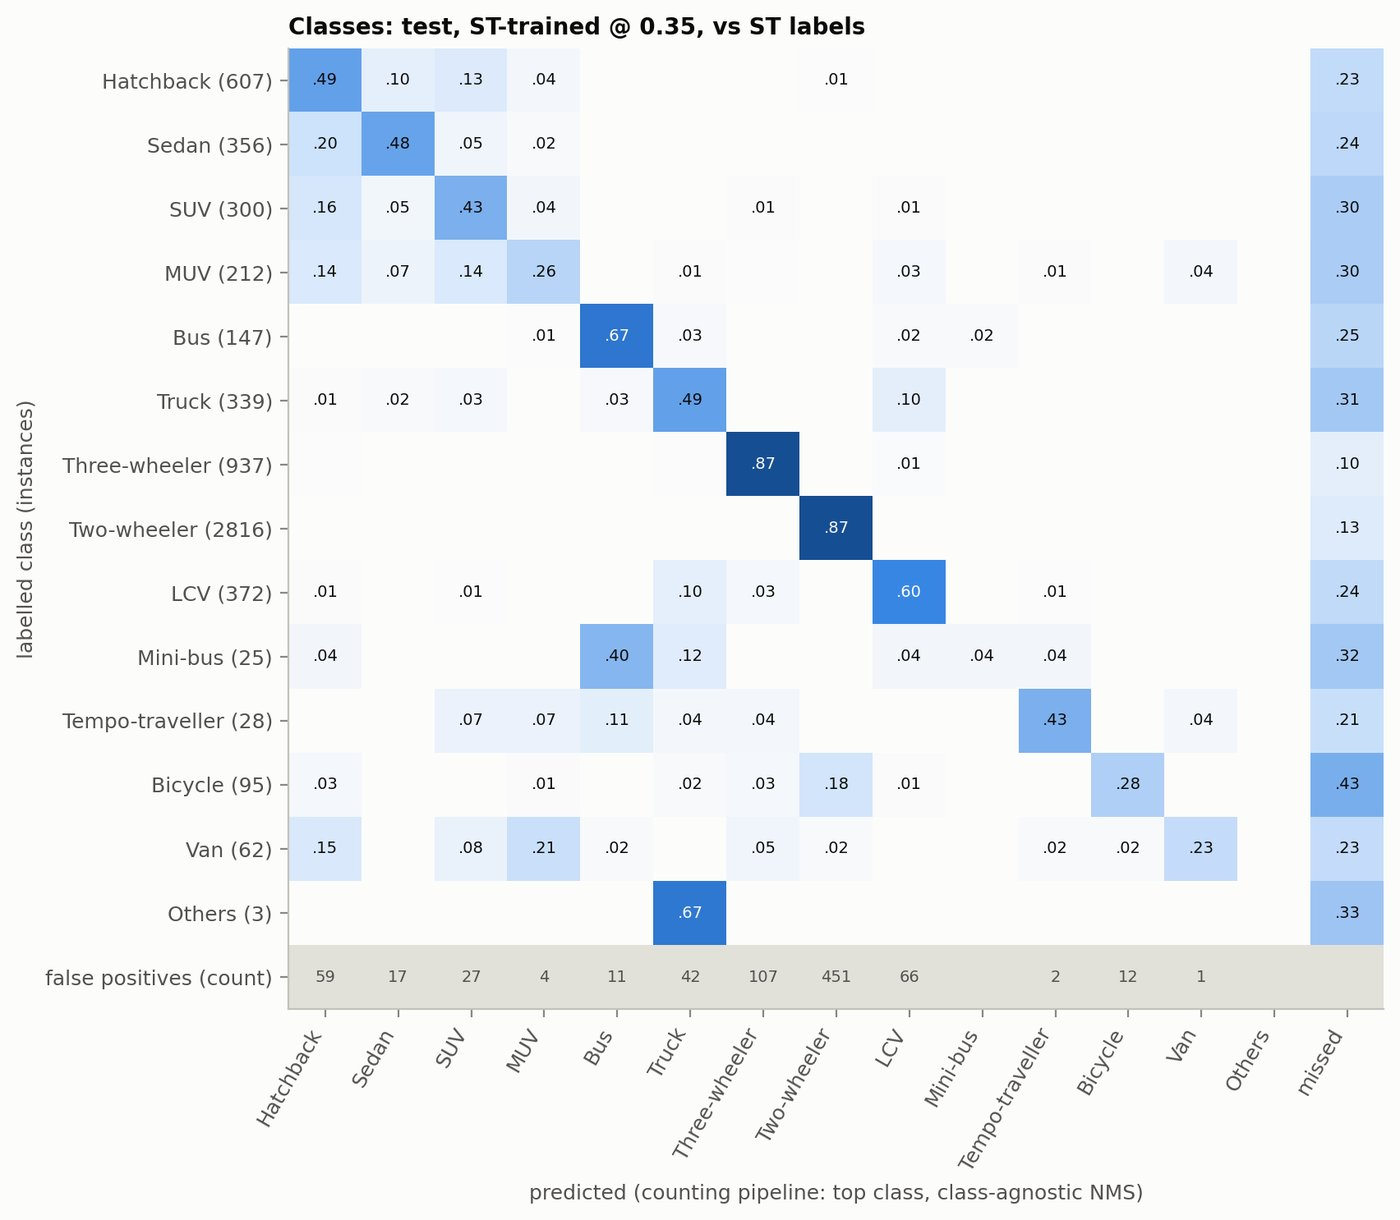

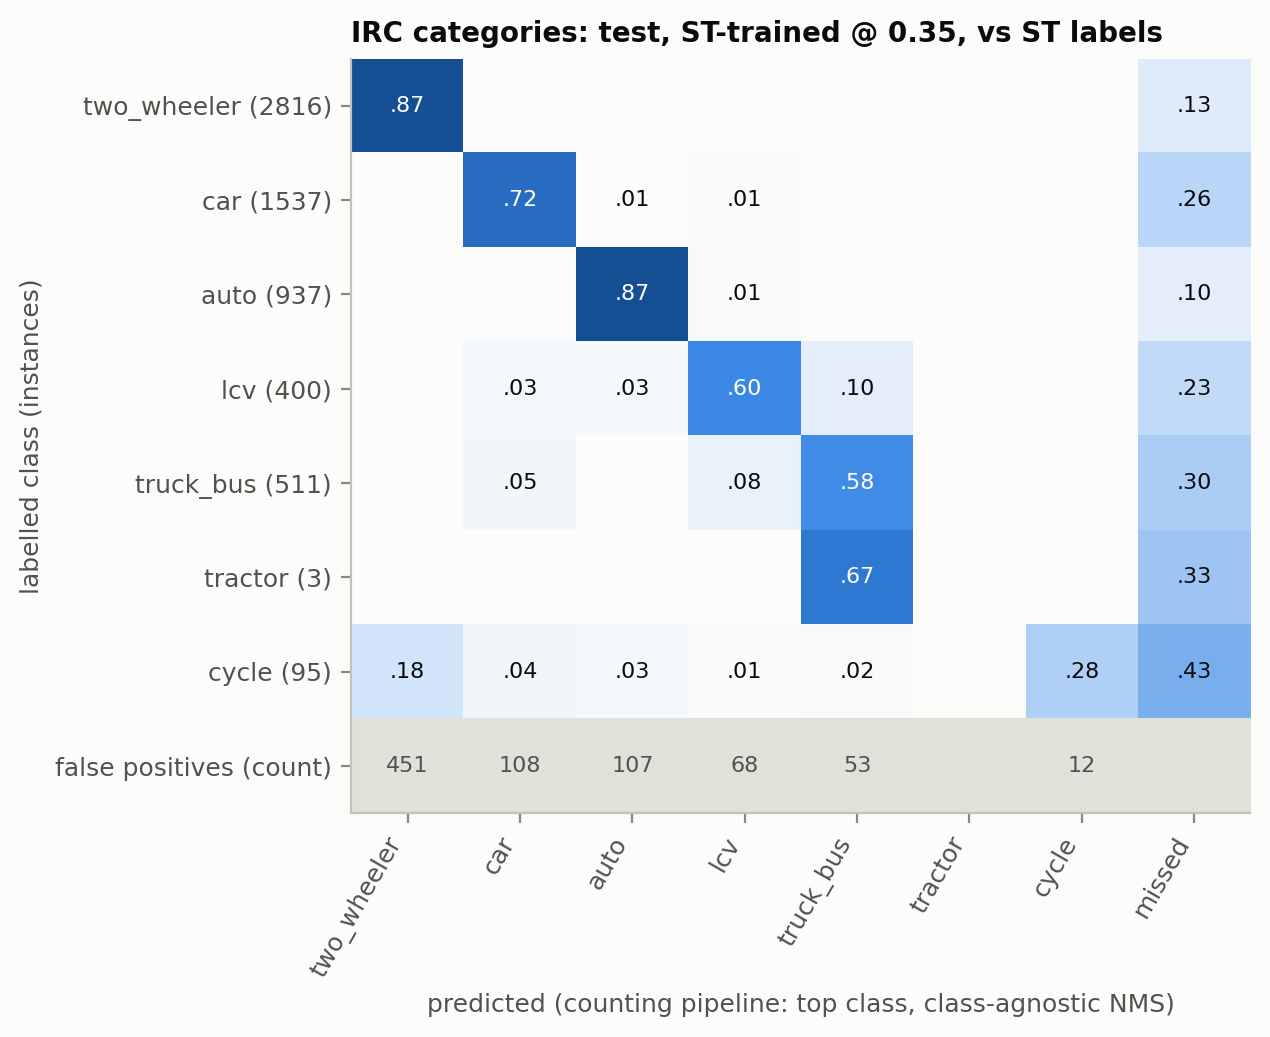

In [26]:
if EVALUATE_TEST:
    evaluate.plot_pr_curves(cfg, {"trained on MV": "mv__test__st", "trained on STAPLE": "st__test__st"},
                            "Test, scored against STAPLE labels", FIGS / "pr_curves_test.png")
    display(Image(filename=str(FIGS / "pr_curves_test.png"), width=560))
    for tr in ("mv", "st"):
        cm = counts.confusion(cfg, tr, "test", allow_test=True)
        for level, width in (("class", 760), ("category", 520)):
            f = FIGS / f"confusion_{level}_{tr}_test.png"
            counts.plot_confusion(cm, f, level)
            display(Image(filename=str(f), width=width))

## 7. Error analysis

The failures of the counting pipeline exactly as evaluated on test: `errors.model` at its frozen threshold, judged against STAPLE labels. Test images are ranked by absolute PCU error and by missed vehicles, and the 30 worst (alternating between the two rankings) are rendered with every box coloured by outcome:

- **aqua**: predicted, class correct
- **orange**: predicted, wrong class, shown as `PRED (true)`
- **red**: labelled vehicle that was missed
- **violet**: prediction with no labelled vehicle (`CLASS?`)

The header of each image gives the PCU error, the counts, and cues for tagging: night/IR frame, missed vehicles that are small (under 24 px tall) or at the frame edge, missed vehicles more than 30% covered by another labelled vehicle, and how many boxes the MV labels have.

In [27]:
if EVALUATE_TEST:
    from src import errors

    err = errors.run(cfg, "test", allow_test=True)
    s = err["summary"]
    print(f"{s['model'].upper()}-trained @ {s['threshold']} vs {s['label_set'].upper()} labels: the {s['worst_n']} worst of "
          f"{s['images']} test images carry {s['share_of_total_abs_pcu_error_in_worst']:.0%} of the total absolute PCU error")
    display(err["worst"].drop(columns=["brightness"]).set_index("rank"))

MV-trained @ 0.35 vs ST labels: the 30 worst of 477 test images carry 24% of the total absolute PCU error


,stem,picked_by,pcu_true,pcu_pred,pcu_err,abs_pcu_err,vehicles_true,vehicles_pred,missed,wrong_class,false_pos,pcu_from_wrong_class,missed_small,missed_at_edge,missed_median_h_px,missed_occluded,missed_not_in_mv,fp_in_mv,boxes_mv,night_ir
rank,,,,,,,,,,,,,,,,,,,,
1,785597,PCU error + missed,27.058,10.750,-16.308,16.308,19,10,10,2,1,1.000,0,1,95.000,3,2,0,15,False
2,1904,missed + PCU error,54.342,39.500,-14.842,14.842,49,38,14,7,3,-5.552,0,1,39.667,8,0,0,44,False
3,217500,missed + PCU error,55.592,45.052,-10.540,10.540,46,36,11,4,1,0.000,0,0,42.000,7,0,0,43,False
4,416055,PCU error + missed,25.158,12.276,-12.882,12.882,16,10,7,2,1,-0.540,0,2,108.667,4,2,0,12,False
5,853707,missed + PCU error,33.196,23.330,-9.866,9.866,28,20,11,3,3,1.600,0,2,47.334,10,2,0,21,False
6,845401,PCU error + missed,30.948,18.330,-12.618,12.618,22,17,7,2,2,-1.736,0,2,145.333,4,0,0,19,False
7,148550,PCU error,23.868,36.448,12.580,12.580,15,23,1,1,9,0.000,0,0,69.333,1,0,0,14,False
8,772122,missed,67.187,71.071,3.884,3.884,46,47,10,3,11,-0.196,0,1,87.333,7,0,1,43,False
9,137148,PCU error + missed,37.066,25.066,-12.000,12.000,28,19,9,2,0,0.000,0,1,38.000,8,0,0,26,False


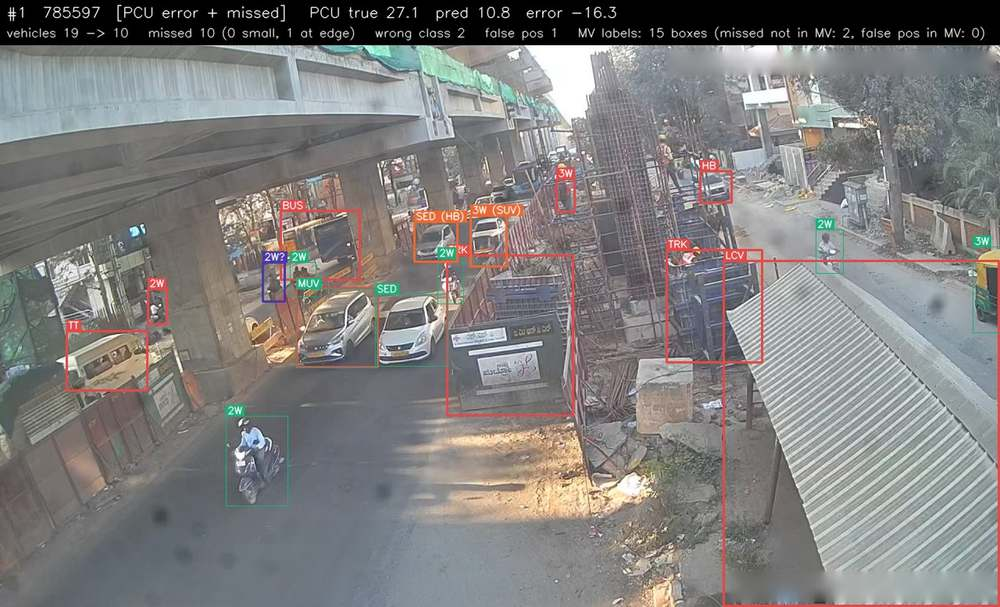

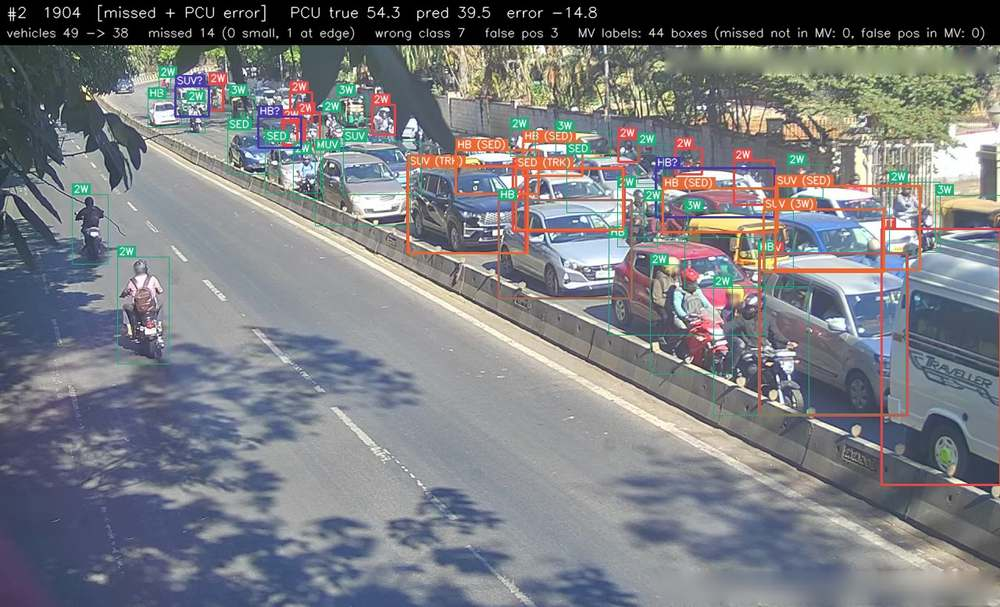

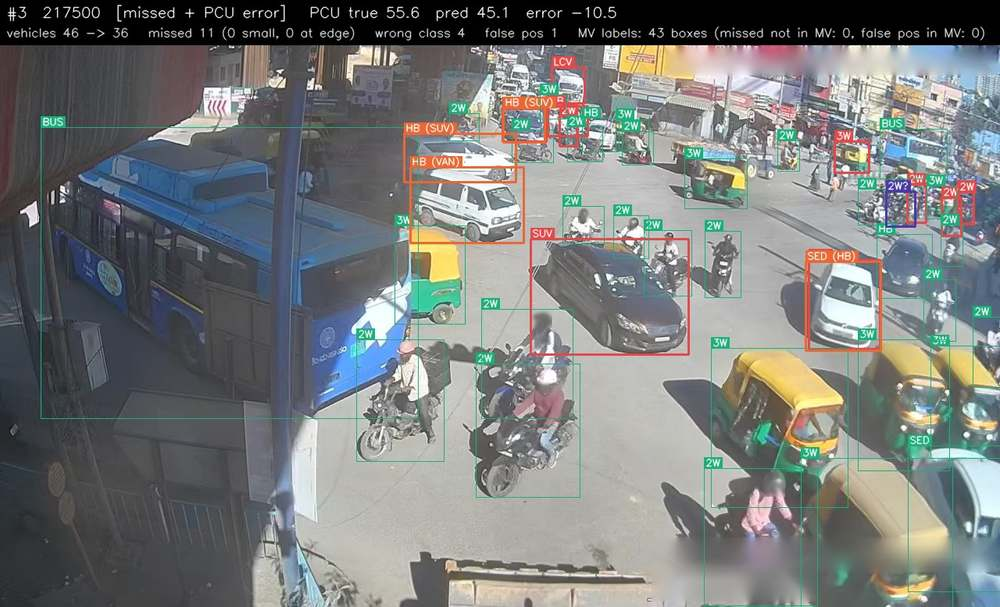

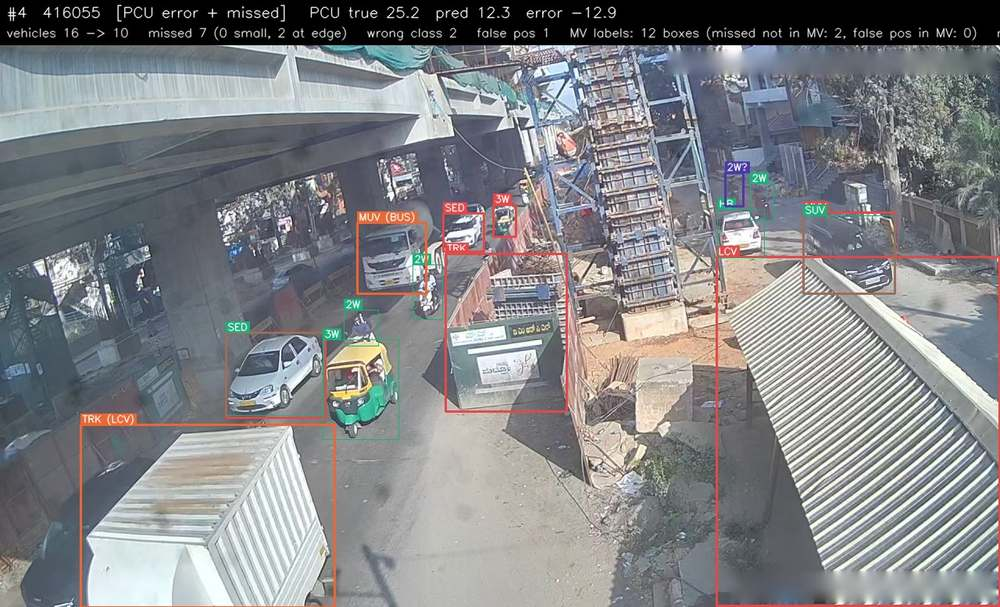

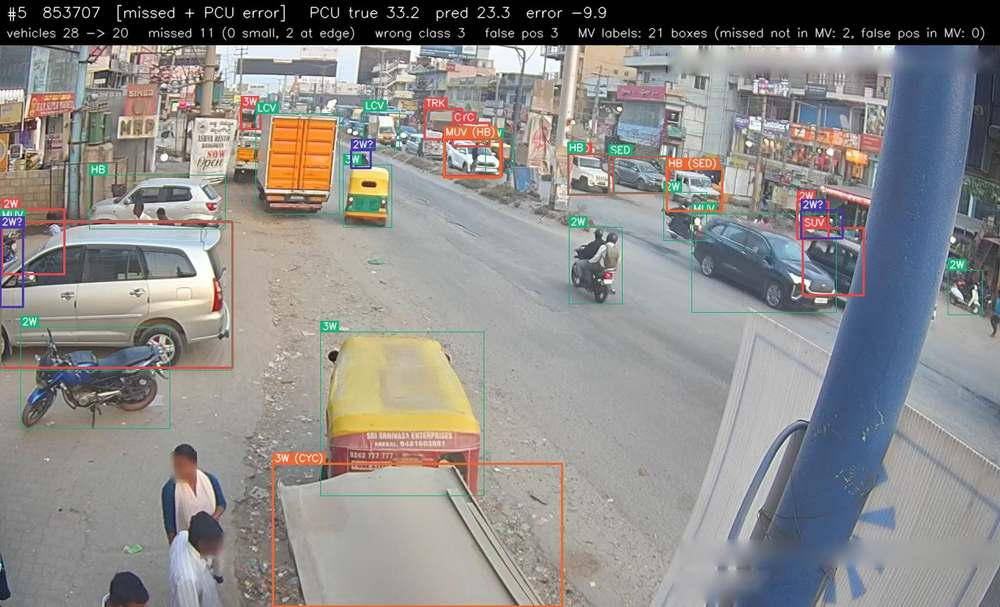

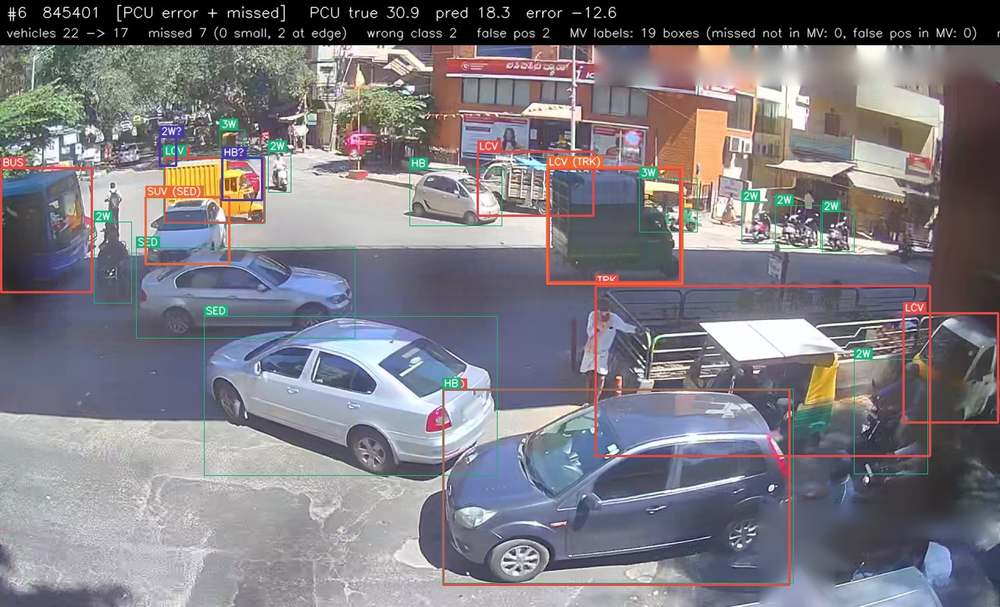

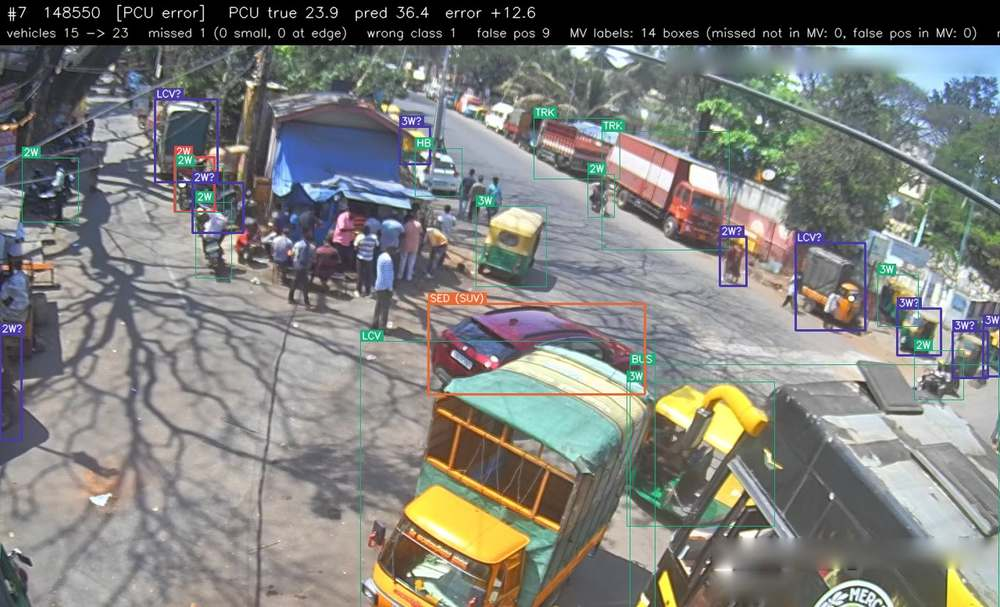

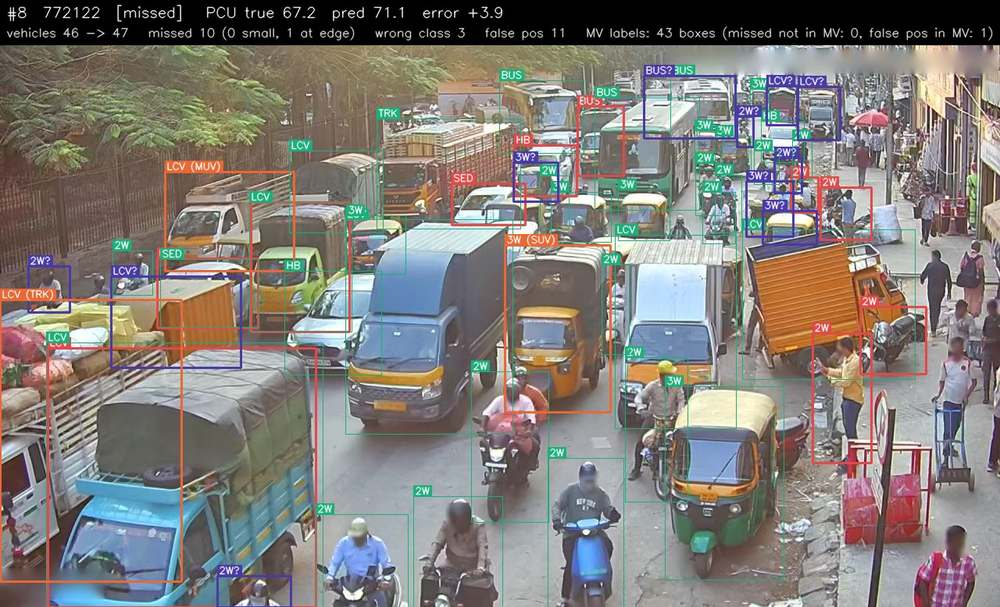

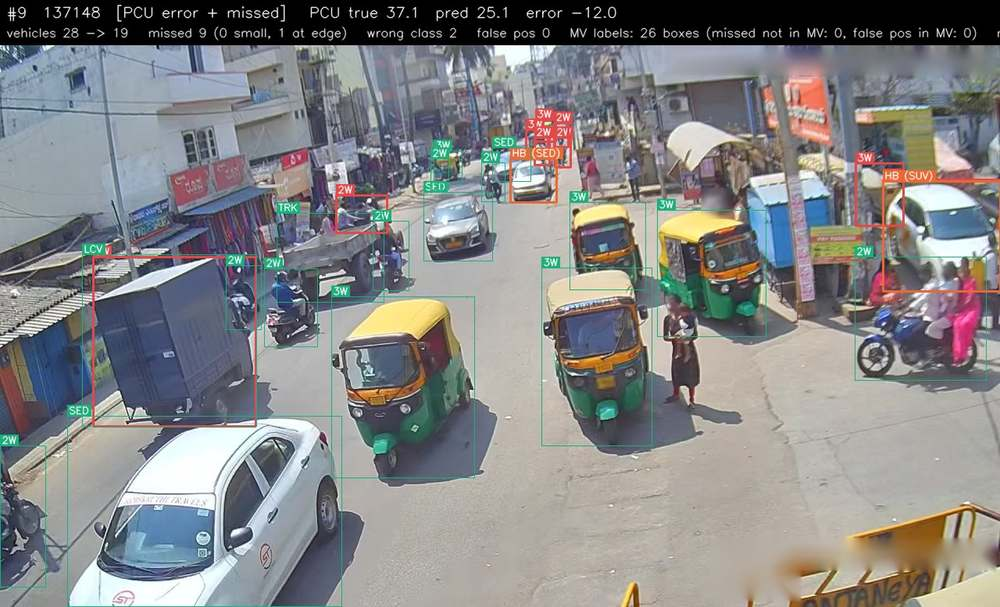

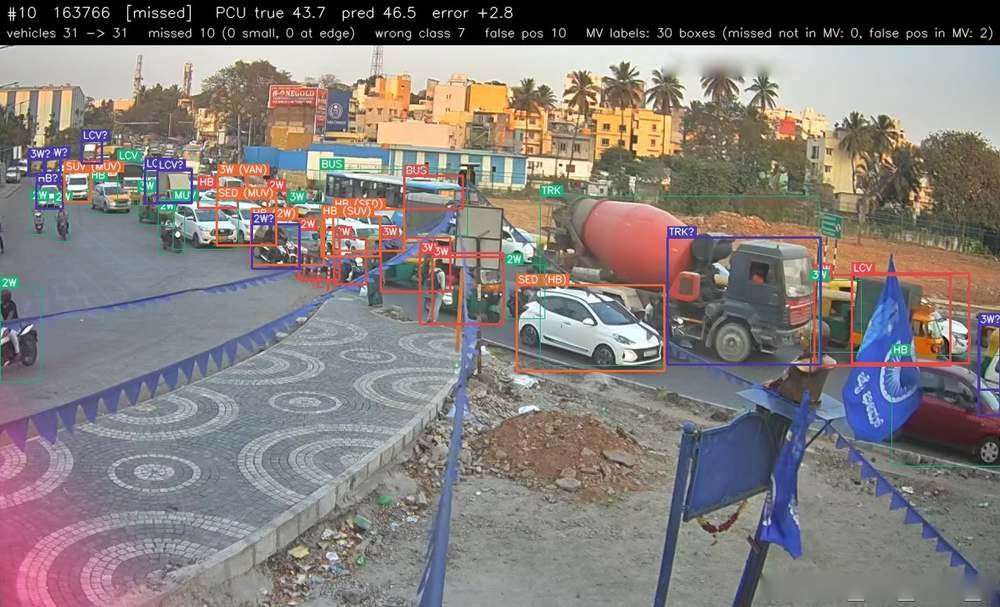

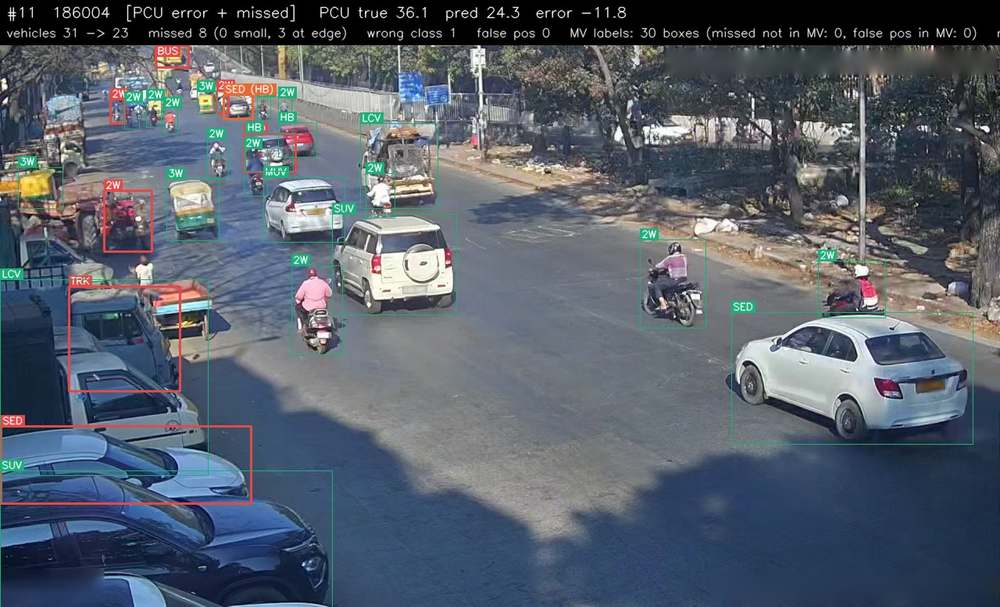

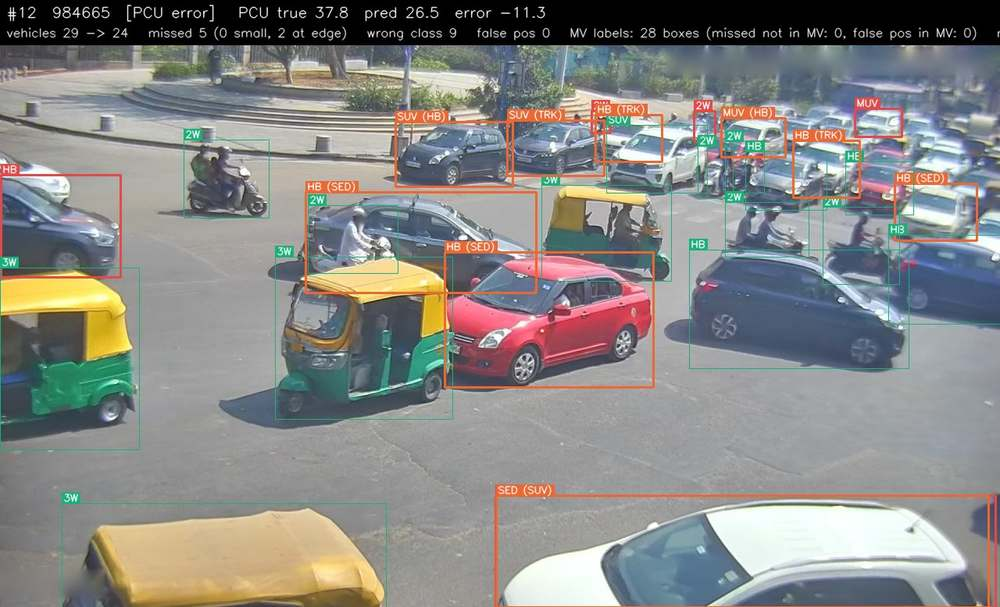

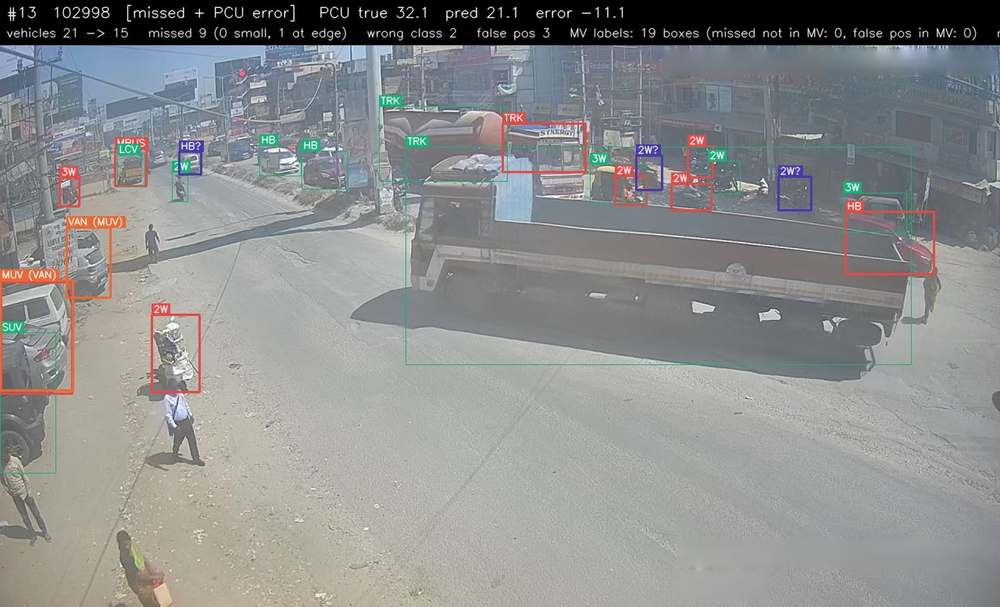

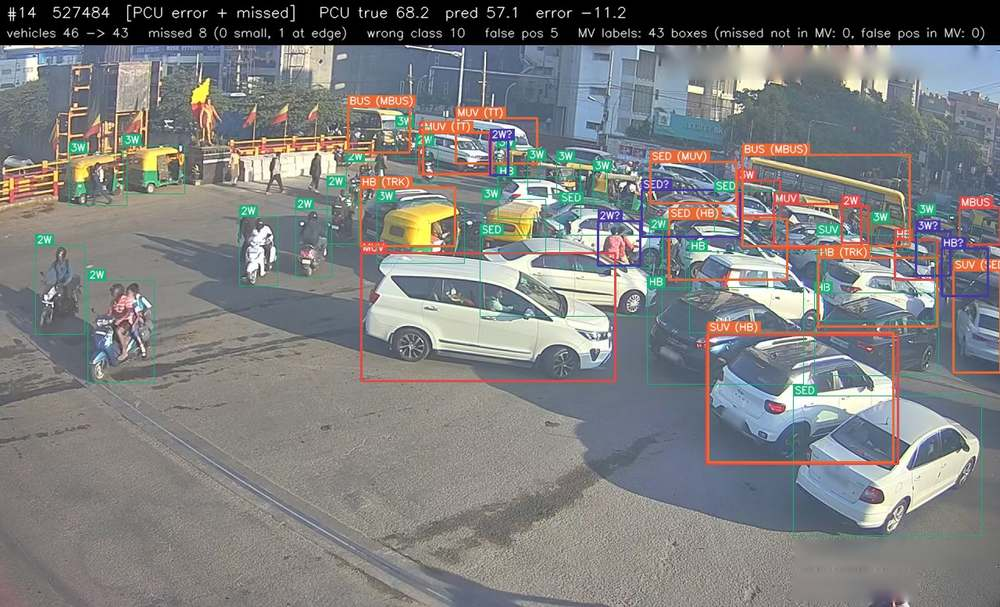

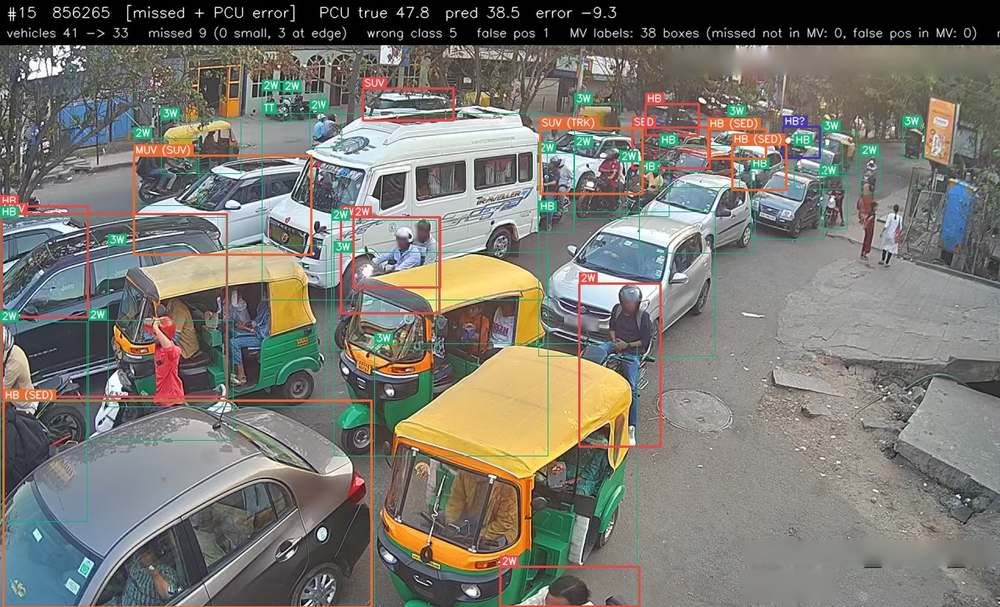

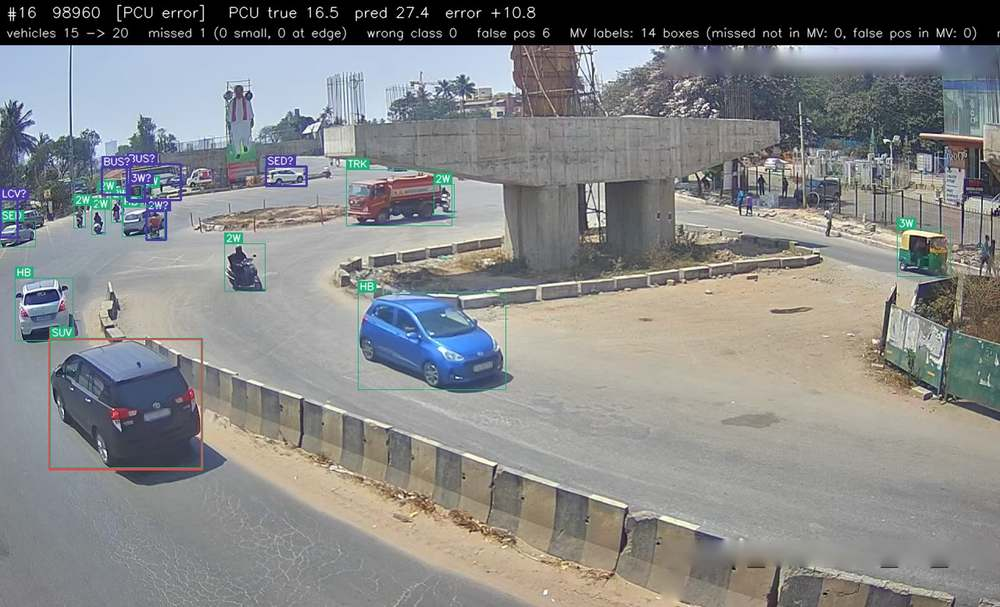

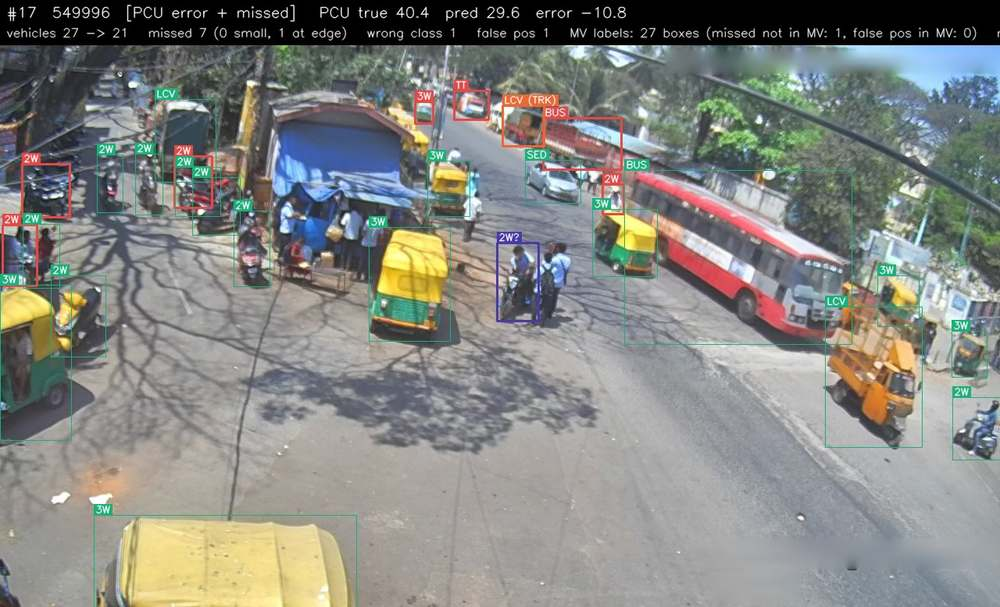

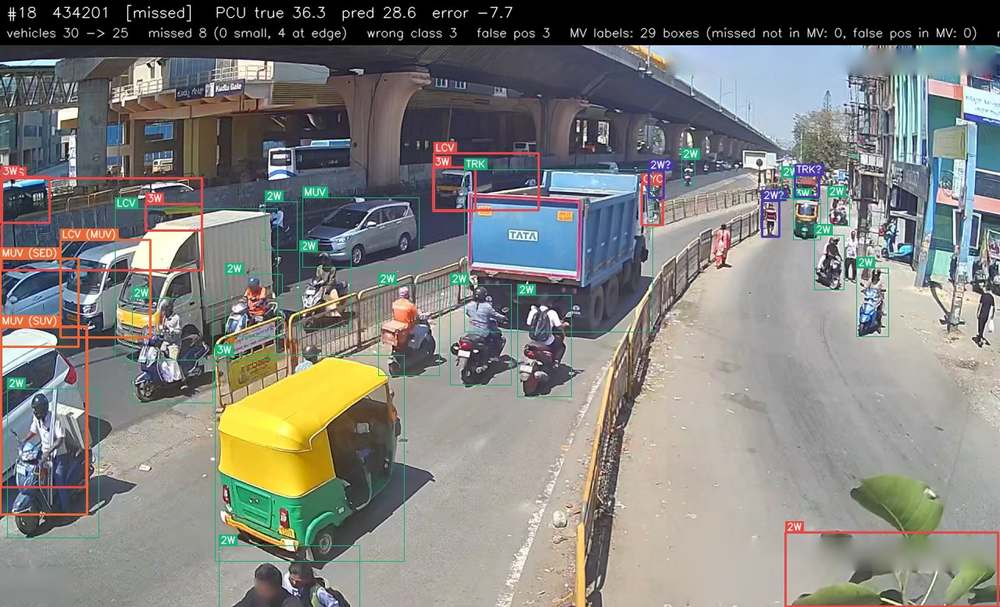

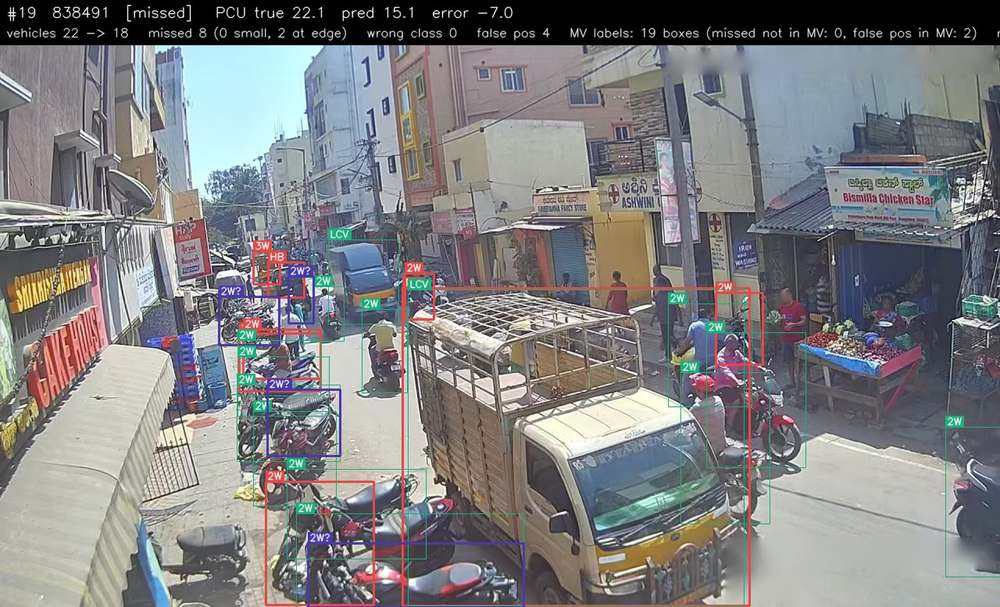

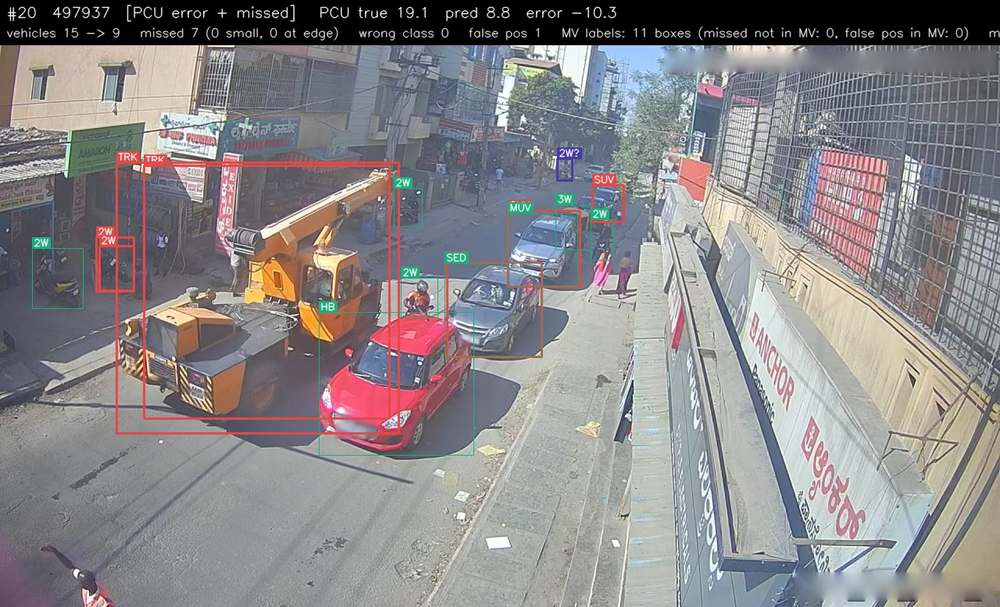

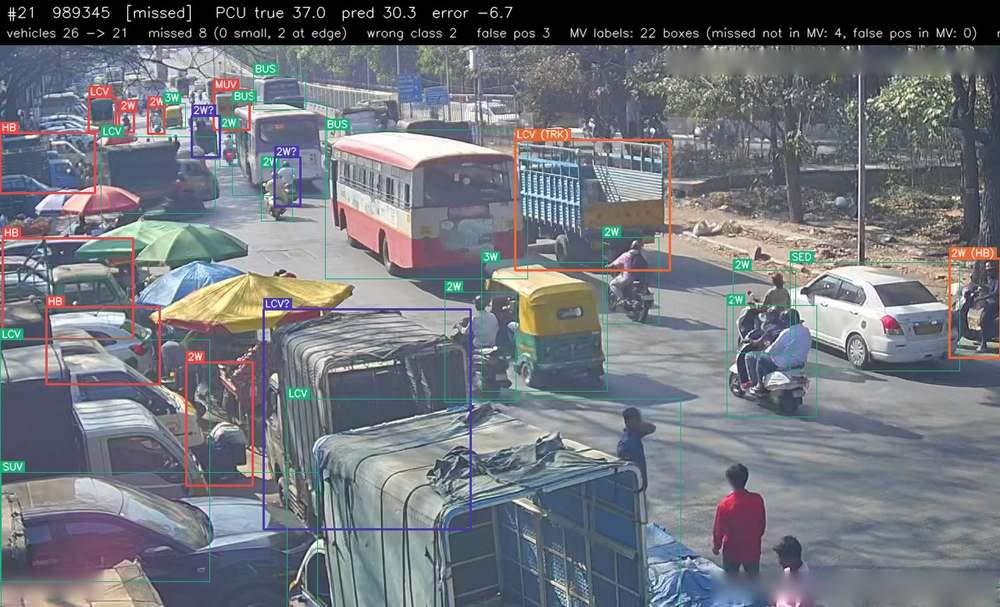

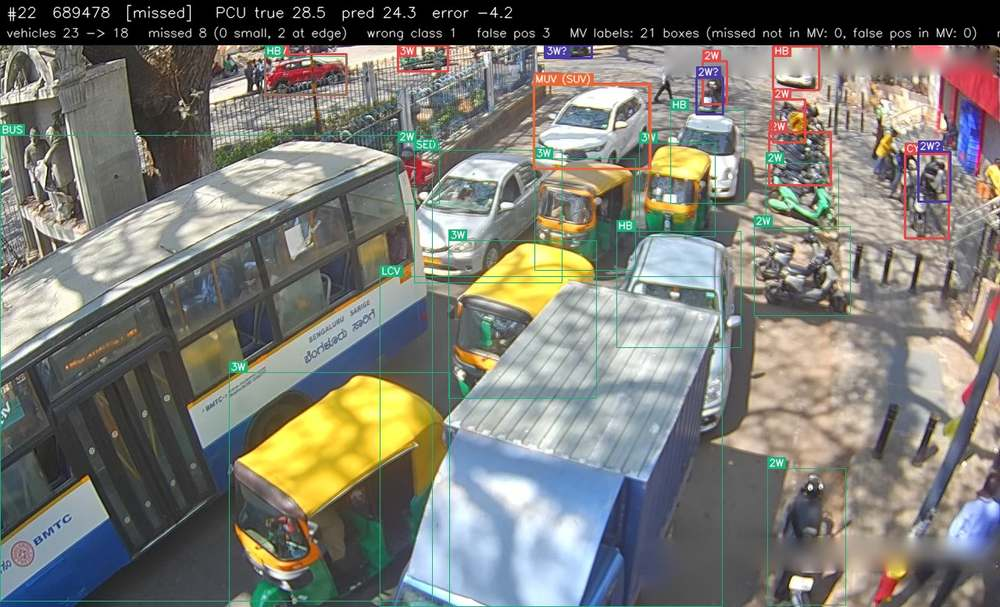

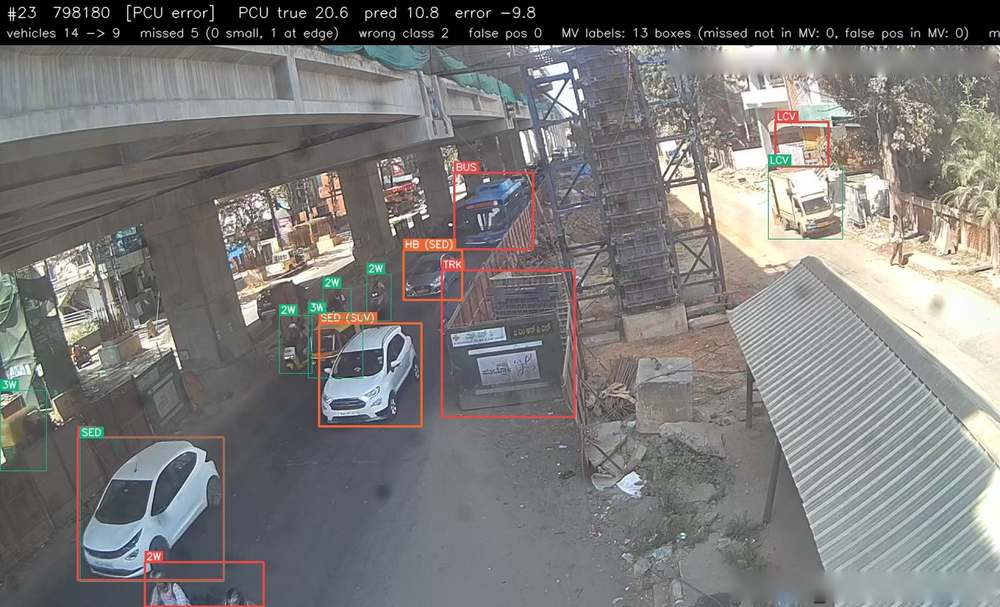

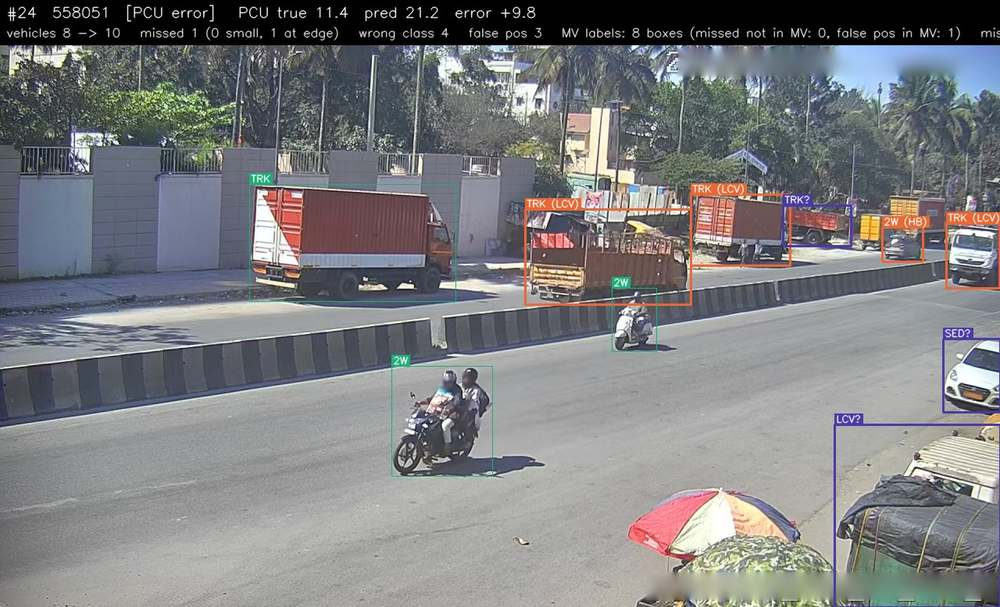

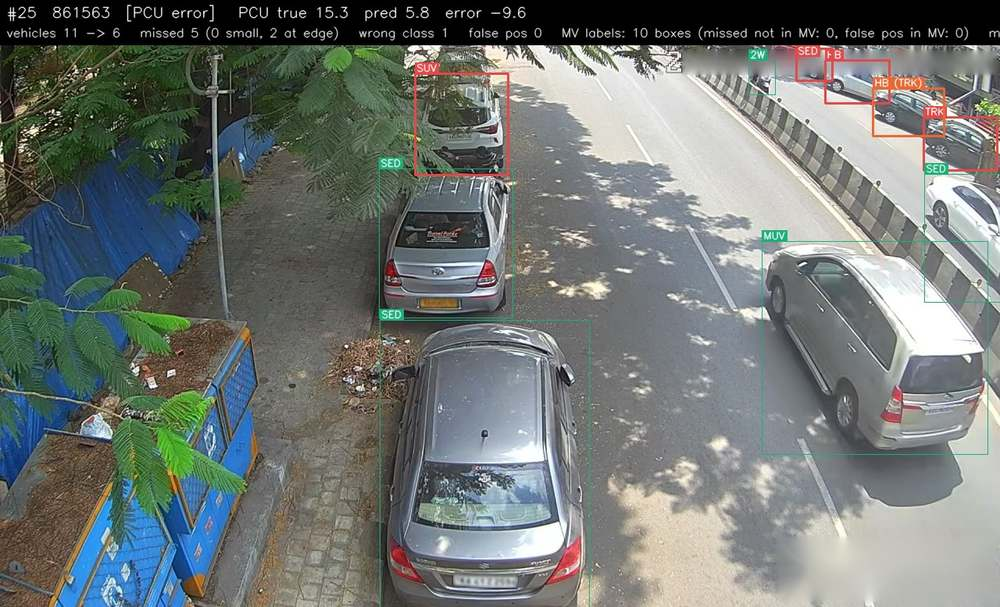

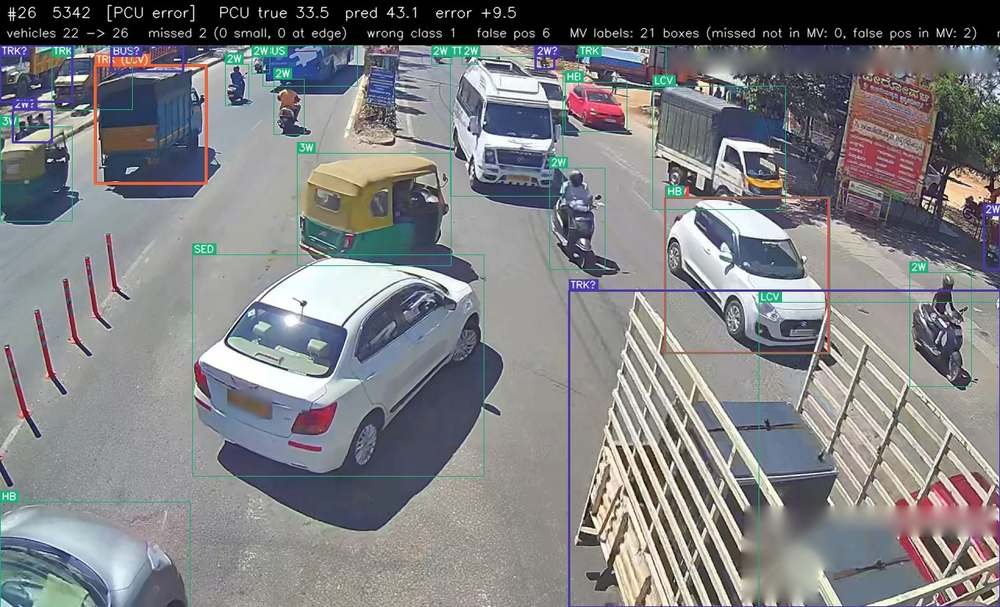

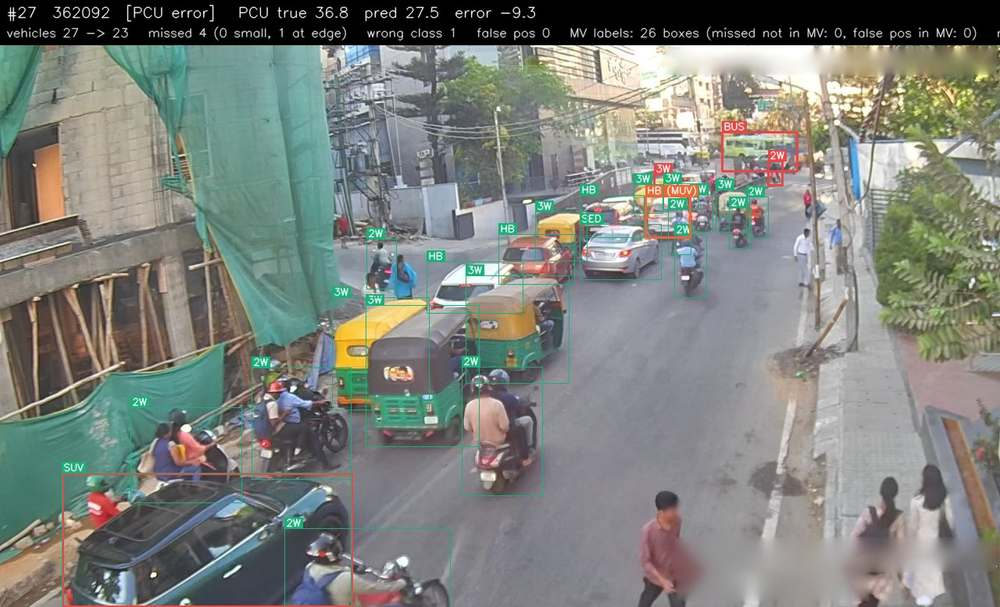

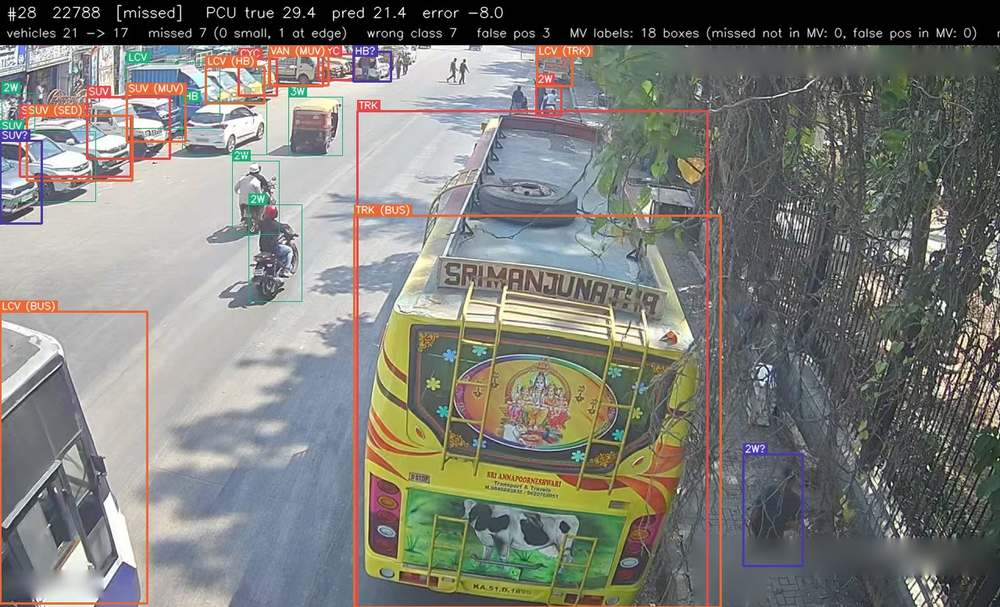

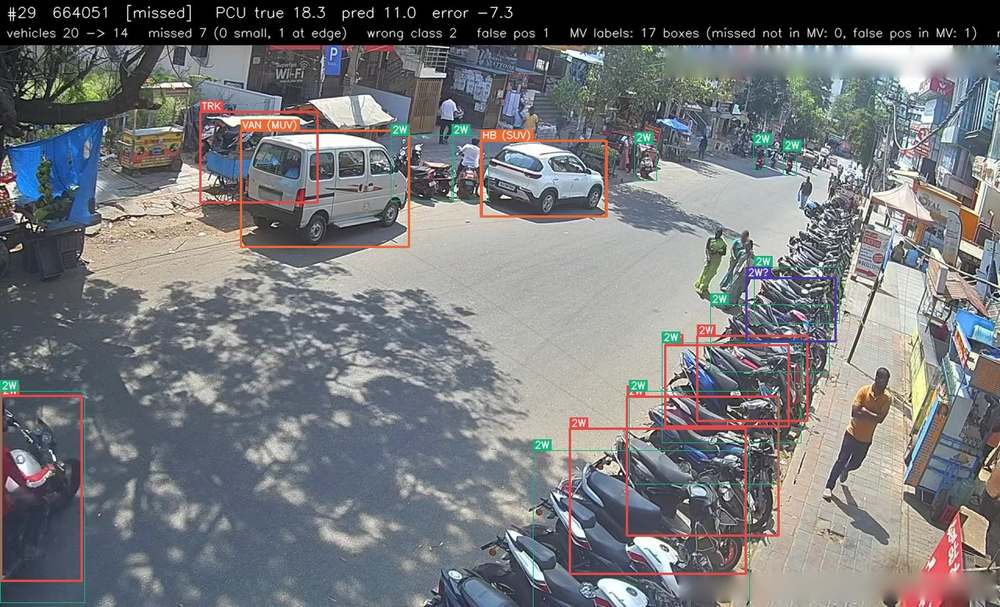

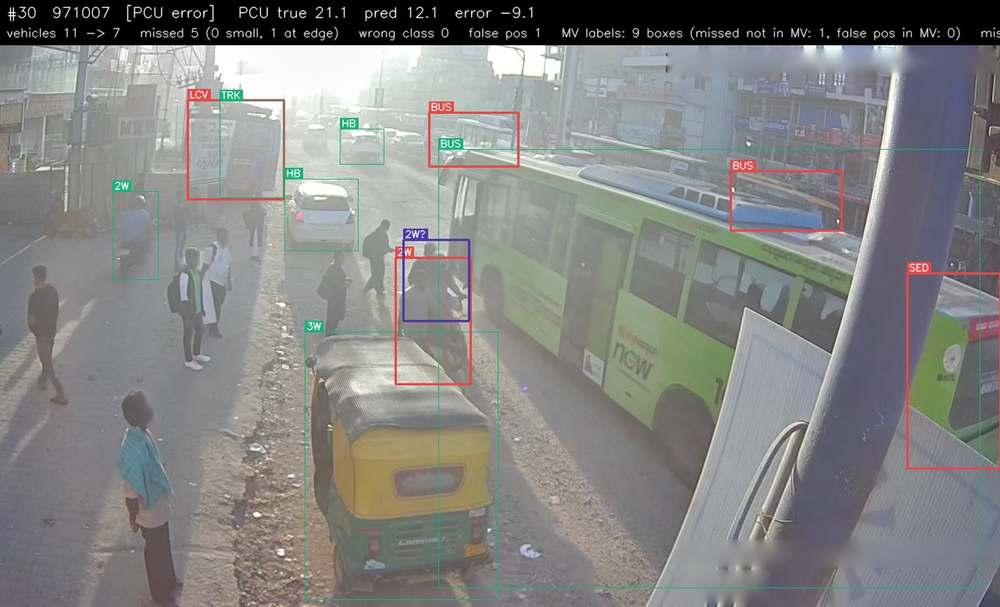

In [28]:
if EVALUATE_TEST:
    for p in err["images"]:
        display(Image(filename=str(p), width=1000))

### Tagging and tally
Each of the 30 images gets one cause, the main reason for its error, from these keys: `occlusion` (dense occlusion), `small` (small or distant vehicle), `confusion` (fine-grained confusion, e.g. Truck vs LCV), `lighting` (lighting or glare), `edge` (cut off at frame edge), `label` (label noise or MV/STAPLE disagreement), `other`. The tags are recorded in `analysis/phase6_tags.csv` (columns `rank, stem, cause, note`); the tally counts them and the PCU error they carry.

30 of 30 images tagged


,images,abs_pcu_err,missed,wrong_class,share_of_images
cause,,,,,
dense occlusion,11,103.274,95,28,0.367
small or distant vehicle,7,66.182,53,18,0.233
cut off at frame edge,5,51.160,30,8,0.167
fine-grained confusion,3,32.260,14,23,0.100
other,2,22.882,8,1,0.067
lighting or glare,1,9.092,5,0,0.033
label noise or MV/STAPLE disagreement,1,8.008,7,7,0.033


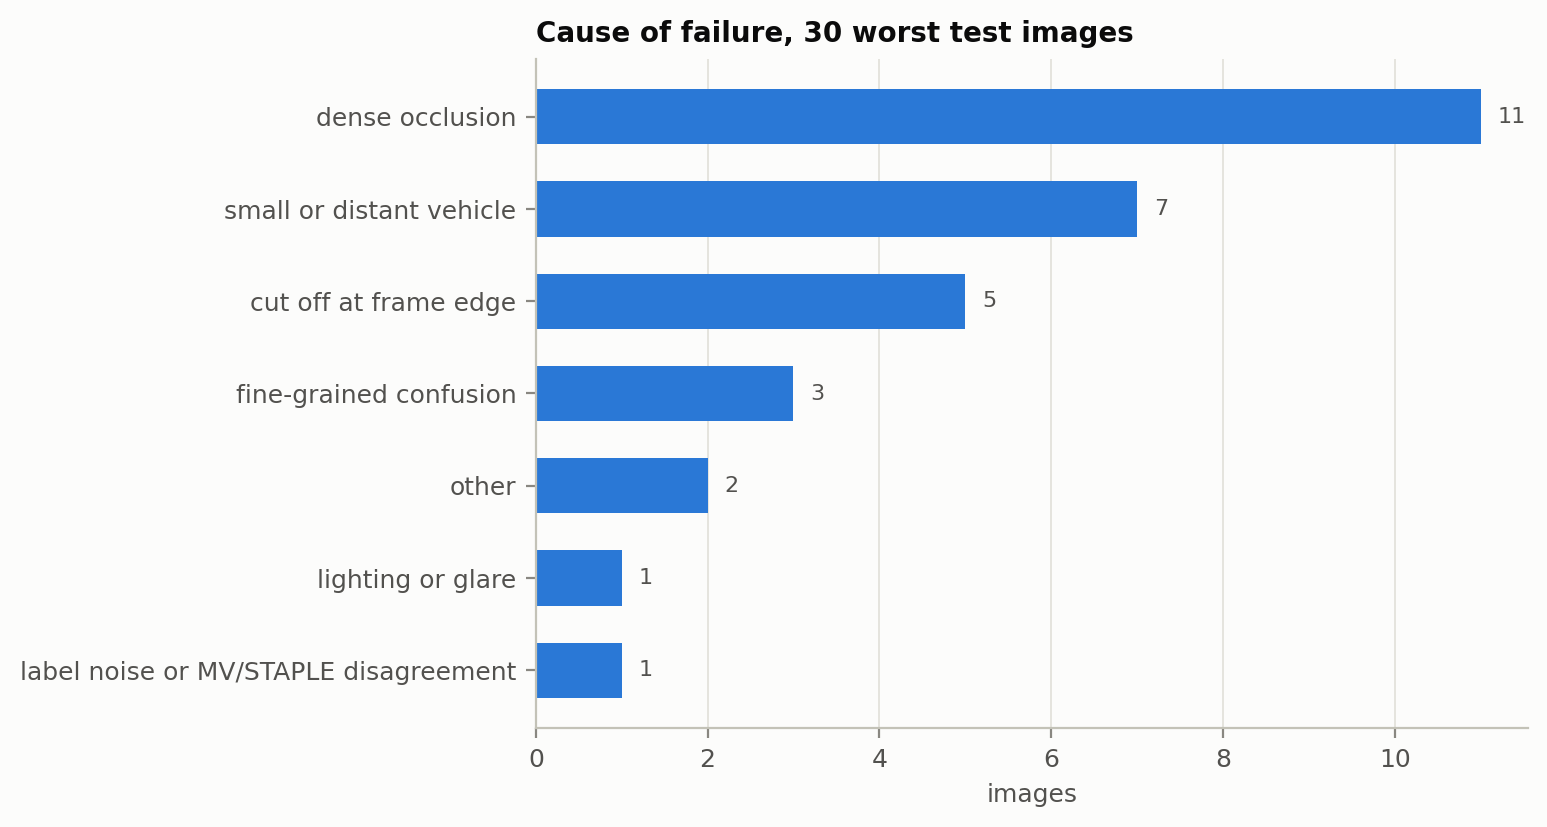

In [29]:
if EVALUATE_TEST:
    tl = errors.tally(cfg)
    if tl is None:
        print("No tags yet:", cfg["paths"]["tags_file"].name)
    else:
        print(f"{tl['tagged']} of {tl['of']} images tagged")
        display(pd.DataFrame(tl["tally"]).set_index("cause"))
        display(Image(filename=str(FIGS / "phase6_tally_test.png"), width=560))

### The dominant failure: occluded vehicles are not counted

Tally of the 30 worst test images (one cause each; tags in `analysis/phase6_tags.csv`, assigned from the rendered images and the per-image cues). Shares are of the 292.9 PCU of absolute error carried by these 30 images.

| Cause | Images | Missed vehicles | Absolute PCU error | Net PCU error |
|---|---|---|---|---|
| Dense occlusion | 11 | 95 | 103.3 (35%) | −95.5 |
| Small or distant vehicle | 7 | 53 | 66.2 (23%) | −38.8 |
| Cut off at frame edge | 5 | 30 | 51.2 (17%) | −32.1 |
| Fine-grained confusion | 3 | 14 | 32.3 (11%) | −12.7 |
| Other (unlabelled parked vehicles, a mobile crane) | 2 | 8 | 22.9 (8%) | +2.3 |
| Lighting (low sun, haze) | 1 | 5 | 9.1 (3%) | −9.1 |
| Label noise (one bus labelled as both Truck and Bus) | 1 | 7 | 8.0 (3%) | −8.0 |

**Pattern.** 24 of the 30 worst images are under-counts. The largest group is vehicles hidden behind other vehicles: queues, rows of parked two-wheelers, and trucks or buses behind hoardings, flyover pillars and market umbrellas. A cue independent of the tags agrees: 139 of the 212 missed vehicles (66%) have more than 30% of their area covered by another labelled vehicle. Hidden heavy vehicles cost the most, because a truck or bus weighs 3.28 PCU. One camera (a construction site under a flyover, images 1, 4 and 23) appears three times. Confusion between classes matters much less for PCU than for mAP: the car classes all weigh 1.0, and only the Truck/LCV boundary (3.28 vs 1.54 PCU) moves the total. Label disagreement between MV and STAPLE explains few failures: only 12 of the 212 misses are vehicles present in the STAPLE labels but not in MV.

## 8. Conclusion

**What I would deploy.** YOLOv8s fine-tuned from COCO on majority-vote labels, counting at confidence 0.35 with one box per vehicle. On the sealed test set (477 frames from pseudo-cameras never used for training or selection) it reaches mAP@0.50:0.95 of 0.489 against MV labels and 0.455 against STAPLE labels. Its PCU error is 2.61 PCU per frame, 15.8% of the mean demand of 16.5 PCU (STAPLE labels), with a bias of −0.93 PCU: the model under-counts. I prefer it to the STAPLE-trained model because their accuracy is equal within noise and its PCU bias is smaller.

**The label-merging ablation.** Training on STAPLE instead of MV labels made no detectable difference: on test against STAPLE labels, −0.007 mAP@0.50:0.95 (95% paired-bootstrap CI −0.023 to +0.008), and −0.014 (−0.035 to +0.011) against MV labels, with PCU errors within 0.1 PCU of each other. The choice of *evaluation* labels moves mAP more than the choice of training labels.

**The number I refuse to promise: the demand of a dense queue.** The worst frames are 10–16 PCU short, almost always under, because occluded heavy vehicles are missed, and dense queues are the approaches that most need green time. Green time set from these counts needs a correction for queue density or a safety margin. I also do not promise per-class counts for the four car body types (only 29–57% on the diagonal of the confusion matrix) or for Mini-bus, Tempo-traveller and Others (fewer than 30 test boxes each), or any performance at night, in rain or outside Bengaluru. About 17% of test frames still have a same-camera frame in training (random audit), so the test numbers may slightly overstate performance on a truly new camera.

**Not done, and why.** No second training seed (about 2 GPU-hours; the bootstrap covers evaluation noise only). Training stopped at 34 epochs while still improving, to fit one free-Colab session; both runs had the same budget, so the comparison stays fair. A planned breakdown of test metrics by similarity to the nearest train frame was not run in time.